# Proyek Analisis Data: [E-Commerce Public Dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)
- **Nama:** Muhammad Gontom Eka Surya
- **Email:** gontom.muhammad@gmail.com
- **ID Dicoding:** DS013B6Y1166

---
## Defining Business Questions

All questions below are explicitly bounded by the dataset coverage period
**October 2016 – August 2018** (~22 months). Each question states the metric
to be measured *and* the business decision it should inform (action-oriented).

- **Question 1 - Monthly Revenue & Order Volume Trend**: 
> How has monthly revenue (in BRL) and order volume evolved month-by-month from October 2016 to August 2018, is there a measurable seasonal pattern (e.g., a November/Black Friday spike), and what does this imply for campaign timing and inventory planning?

- **Question 2 - Product Categories: Revenue vs Customer Satisfaction**: 
> Which product categories generated the highest total revenue during October 2016 – August 2018, did the top-revenue categories achieve a mean review score of at least 4.0 out of 5, and which categories should be prioritised for quality or logistics intervention?

- **Question 3 - Delivery Performance vs Customer Satisfaction**: 
> How did late-delivery rate (%) and average delivery days differ across Brazilian states during October 2016 – August 2018, what was the review-score gap between late and on-time orders, and which states should be prioritised for logistics SLA enforcement?

- **Question 4 - Geographic Distribution of Customers & Revenue**: 
> What share of customers and revenue was concentrated in each Brazilian state during October 2016 – August 2018, which states were under-served (< 1% revenue share), and where should seller recruitment and marketing spend be directed?

- **Question 5 - Payment Behaviour: Type Split & Installment Patterns**: 
> What was the payment-type distribution by order volume during October 2016 – August 2018, how much larger was the average spend of customers paying in 12 installments vs. 1 installment, and should installment financing be expanded at checkout?

### SMART Validation

| Question | Specific | Measurable | Action-Oriented | Relevant | Time-bound |
|---|---|---|---|---|---|
| Q1 Revenue & Order Trend | Monthly revenue + order count only | BRL revenue, order count per month; % spike detection | Informs campaign timing / inventory planning | Core business health metric | Oct 2016 – Aug 2018 (explicit in question) |
| Q2 Category Revenue vs Satisfaction | Top-revenue categories vs review score | Total revenue per category; mean review score (threshold ≥ 4.0) | Prioritises categories for quality/logistics fixes | Directly impacts marketplace trust | Oct 2016 – Aug 2018 (explicit in question) |
| Q3 Delivery vs Satisfaction | Late rate & delivery days by state | Late-delivery %, avg delivery days, review-score gap (points) | Drives per-state SLA enforcement priorities | Delivery is the #1 satisfaction lever | Oct 2016 – Aug 2018 (explicit in question) |
| Q4 Geographic Concentration | Revenue & customer share per state | % revenue share, % customer share per state; <1% = under-served | Guides seller recruitment & ad spend | Revenue diversification / risk | Oct 2016 – Aug 2018 (explicit in question) |
| Q5 Payment Behaviour | Payment type split & installment depth | % share per payment type; avg spend: 12- vs 1-installment buyers | Decides whether to expand installment options | Directly affects basket size / conversion | Oct 2016 – Aug 2018 (explicit in question) |

---
## Import Packages/Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import plotly.express as px
import plotly.graph_objects as go
import os
import warnings; warnings.filterwarnings('ignore')
from plotly.subplots import make_subplots

---
### Gathering Data

#### Load df ...

In [2]:
from src.utils import load_and_inspect_ecommerce_data

# Load all datasets into a dictionary
dfs = load_and_inspect_ecommerce_data("data/E-Commerce_Public_Dataset")


Dataset: customers_dataset.csv
[Duplicate Check] No duplicate rows found.
Row count -> Before: 99,441 | After: 99,441
Primary Key Status: No single column satisfies strict uniqueness and non-null constraints (likely uses a composite key).

Dataset: geolocation_dataset.csv
[Duplicate Check] Removed 261831 duplicate rows.
Row count -> Before: 1,000,163 | After: 738,332
Primary Key Status: No single column satisfies strict uniqueness and non-null constraints (likely uses a composite key).

Dataset: order_items_dataset.csv
[Duplicate Check] No duplicate rows found.
Row count -> Before: 112,650 | After: 112,650
Primary Key Status: No single column satisfies strict uniqueness and non-null constraints (likely uses a composite key).

Dataset: order_payments_dataset.csv
[Duplicate Check] No duplicate rows found.
Row count -> Before: 103,886 | After: 103,886
Primary Key Status: No single column satisfies strict uniqueness and non-null constraints (likely uses a composite key).

Dataset: order_r

![DB Schema](./db-schema.png)

### Assessing Data

#### Identifying data problem

<br>

### Step 1 -- Aggregate `order_reviews` -> one row per `order_id`

In [3]:
# ── Step 1: Aggregate `order_reviews` -> one row per `order_id` ──────────────────
# Multiple reviews can exist for the same order; keep the mean score and the
# most recent review creation date.
order_reviews_df = dfs["order_reviews_dataset.csv"] # adjust the original file name

print(f"order_reviews shape: {order_reviews_df.shape}")
display(order_reviews_df.head())
print("==="*9)
reviews_agg = (
    order_reviews_df
    .groupby("order_id", as_index=False)
    .agg(
        review_score=("review_score", "mean"),
        review_count=("review_score", "count"),
        review_creation_date=("review_creation_date", "max"),
    )
)
print(f"reviews_agg shape: {reviews_agg.shape}")
reviews_agg.head()

order_reviews shape: (99224, 7)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


reviews_agg shape: (98673, 4)


,order_id,review_score,review_count,review_creation_date
0,00010242fe8c5a6d1ba2dd792cb16214,5.0,1,2017-09-21 00:00:00
1,00018f77f2f0320c557190d7a144bdd3,4.0,1,2017-05-13 00:00:00
2,000229ec398224ef6ca0657da4fc703e,5.0,1,2018-01-23 00:00:00
3,00024acbcdf0a6daa1e931b038114c75,4.0,1,2018-08-15 00:00:00
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0,1,2017-03-02 00:00:00


<br>

### Step 2 -- Aggregate `order_payments` -> one row per `order_id`

In [4]:
# ── Step 2: Aggregate `order_payments` -> one row per `order_id` ─────────────────
# An order can be paid with multiple payment methods (`payment_sequential` > 1).
# We sum the payment_value and collect the distinct payment types.
order_payments_df = dfs["order_payments_dataset.csv"]

print(f"order_payments shape: {order_payments_df.shape}")
display(order_payments_df.head())
print("==="*9)

payments_agg = (
    order_payments_df
    .groupby("order_id", as_index=False)
    .agg(
        payment_total_value=("payment_value", "sum"),
        payment_installments=("payment_installments", "max"),
        payment_types=("payment_type", lambda x: ", ".join(sorted(x.unique()))),
    )
)
print(f"payments_agg shape: {payments_agg.shape}")
payments_agg.head()

order_payments shape: (103886, 5)


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


payments_agg shape: (99440, 4)


,order_id,payment_total_value,payment_installments,payment_types
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,2,credit_card
1,00018f77f2f0320c557190d7a144bdd3,259.83,3,credit_card
2,000229ec398224ef6ca0657da4fc703e,216.87,5,credit_card
3,00024acbcdf0a6daa1e931b038114c75,25.78,2,credit_card
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,3,credit_card


<br>

### Step 3 -- Aggregate geolocation -> one row per `zip_code_prefix`

In [5]:
# ── Step 3: Aggregate geolocation -> one row per `zip_code_prefix` ─────────────
# geolocation has no unique key (many lat/lng entries per zip).
# We take the mean coordinates per zip to get a single representative point.
geolocation_df = dfs["geolocation_dataset.csv"]

print(f"geolocation shape: {geolocation_df.shape}")
display(geolocation_df.head())
print("==="*9)

geo_agg = (
    geolocation_df
    .groupby("geolocation_zip_code_prefix", as_index=False)
    .agg(
        geolocation_lat=("geolocation_lat", "mean"),
        geolocation_lng=("geolocation_lng", "mean"),
    )
)
print(f"geo_agg shape: {geo_agg.shape}")
geo_agg.head()

geolocation shape: (738332, 5)


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


geo_agg shape: (19015, 3)


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
0,1001,-23.550227,-46.634039
1,1002,-23.547657,-46.634991
2,1003,-23.549000,-46.635582
3,1004,-23.549829,-46.634792
4,1005,-23.549547,-46.636406


<br>

### Step 4 -- Enrich customers with geolocation

In [6]:
# ── Step 4: Enrich customers with geolocation ────────────────────────────────
customers_df = dfs["customers_dataset.csv"]

print(f"customers_df shape: {customers_df.shape}")
display(customers_df.head())
print("==="*9)

customers_geo = customers_df.merge(
    geo_agg,
    left_on="customer_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left",
).drop(columns=["geolocation_zip_code_prefix"])

# Rename lat/lng to make the source clear
customers_geo = customers_geo.rename(
    columns={
        "geolocation_lat": "customer_lat",
        "geolocation_lng": "customer_lng",
    }
)
print(f"customers_geo shape: {customers_geo.shape}")
customers_geo.head()

customers_df shape: (99441, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


customers_geo shape: (99441, 7)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,customer_lat,customer_lng
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,-20.499273,-47.396658
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,-23.728396,-46.542250
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,-23.531309,-46.656690
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,-23.500670,-46.186348
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,-22.975708,-47.143140


<br>

### Step 5 -- Enrich sellers with geolocation

In [7]:
# ── Step 5: Enrich sellers with geolocation ──────────────────────────────────
sellers_df = dfs["sellers_dataset.csv"]

print(f"sellers_df shape: {sellers_df.shape}")
display(sellers_df.head())
print("==="*9)

sellers_geo = sellers_df.merge(
    geo_agg,
    left_on="seller_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left",
).drop(columns=["geolocation_zip_code_prefix"])

sellers_geo = sellers_geo.rename(
    columns={
        "geolocation_lat": "seller_lat",
        "geolocation_lng": "seller_lng",
    }
)

print(f"sellers_geo shape: {sellers_geo.shape}")
sellers_geo.head()

sellers_df shape: (3095, 4)


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


sellers_geo shape: (3095, 6)


,seller_id,seller_zip_code_prefix,seller_city,seller_state,seller_lat,seller_lng
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP,-22.893317,-47.060596
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP,-22.383375,-46.948142
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ,-22.909446,-43.180240
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP,-23.657118,-46.612730
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP,-22.964546,-46.534214


<br>

### Step 6 -- Enrich products with English category names

In [8]:
# ── Step 6: Enrich products with English category names ──────────────────────
products_df = dfs["products_dataset.csv"]
product_category_df = dfs["product_category_name_translation.csv"]

print(f"products_df shape: {products_df.shape}")
display(products_df.head())
print("==="*9)

print(f"product_category_df shape: {product_category_df.shape}")
display(product_category_df.head())
print("==="*9)

products_translated = products_df.merge(
    product_category_df,
    on="product_category_name",
    how="left",
).drop(columns=["product_category_name"])

products_translated = products_translated.rename(
    columns={
        "product_category_name_english": "product_category_name",
    }
)

print(f"products_translated shape: {products_translated.shape}")
products_translated.head()

products_df shape: (32951, 9)


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


product_category_df shape: (71, 2)


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


products_translated shape: (32951, 9)


,product_id,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name
0,1e9e8ef04dbcff4541ed26657ea517e5,40.0,287.0,1.0,225.0,16.0,10.0,14.0,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,art
2,96bd76ec8810374ed1b65e291975717f,46.0,250.0,1.0,154.0,18.0,9.0,15.0,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,27.0,261.0,1.0,371.0,26.0,4.0,26.0,baby
4,9dc1a7de274444849c219cff195d0b71,37.0,402.0,4.0,625.0,20.0,17.0,13.0,housewares


<br>

### Step 7 -- Build the master DataFrame

In [9]:
# ── Step 7: Build the master DataFrame ──────────────────────────────────────
# Grain: one row per order item (`order_id` + `order_item_id`).
# Join chain:
#   order_items
#     > orders              (order_id)
#     > customers_geo       (customer_id)
#     > products_translated (product_id)
#     > sellers_geo         (seller_id)
#     > payments_agg        (order_id)
#     > reviews_agg         (order_id)

order_items_df = dfs["order_items_dataset.csv"]
orders_df = dfs["orders_dataset.csv"]

master_df = (
    order_items_df
    # orders (brings order status + timestamps)
    .merge(orders_df, on="order_id", how="left")
    # customers + geolocation
    .merge(customers_geo, on="customer_id", how="left")
    # products + English category name
    .merge(products_translated, on="product_id", how="left")
    # sellers + geolocation
    .merge(sellers_geo, on="seller_id", how="left")
    # aggregated payments
    .merge(payments_agg, on="order_id", how="left")
    # aggregated reviews
    .merge(reviews_agg, on="order_id", how="left")
)
pd.set_option("display.max_columns", None)
print(f"master_df shape: {master_df.shape}")
display(master_df.head())
master_df.columns.tolist()

master_df shape: (112650, 39)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,customer_lat,customer_lng,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name,seller_zip_code_prefix,seller_city,seller_state,seller_lat,seller_lng,payment_total_value,payment_installments,payment_types,review_score,review_count,review_creation_date
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29 00:00:00,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,RJ,-21.763186,-41.310265,58.0,598.0,4.0,650.0,28.0,9.0,14.0,cool_stuff,27277,volta redonda,SP,-22.497188,-44.127324,72.19,2.0,credit_card,5.0,1.0,2017-09-21 00:00:00
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15 00:00:00,eb28e67c4c0b83846050ddfb8a35d051,15775,santa fe do sul,SP,-20.222506,-50.898951,56.0,239.0,2.0,30000.0,50.0,30.0,40.0,pet_shop,3471,sao paulo,SP,-23.565754,-46.519097,259.83,3.0,credit_card,4.0,1.0,2017-05-13 00:00:00
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05 00:00:00,3818d81c6709e39d06b2738a8d3a2474,35661,para de minas,MG,-19.869998,-44.593059,59.0,695.0,2.0,3050.0,33.0,13.0,33.0,furniture_decor,37564,borda da mata,MG,-22.262802,-46.170735,216.87,5.0,credit_card,5.0,1.0,2018-01-23 00:00:00
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20 00:00:00,af861d436cfc08b2c2ddefd0ba074622,12952,atibaia,SP,-23.105968,-46.590277,42.0,480.0,1.0,200.0,16.0,10.0,15.0,perfumery,14403,franca,SP,-20.553651,-47.387145,25.78,2.0,credit_card,4.0,1.0,2018-08-15 00:00:00
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17 00:00:00,64b576fb70d441e8f1b2d7d446e483c5,13226,varzea paulista,SP,-23.243402,-46.827614,59.0,409.0,1.0,3750.0,35.0,40.0,30.0,garden_tools,87900,loanda,PR,-22.929583,-53.135750,218.04,3.0,credit_card,5.0,1.0,2017-03-02 00:00:00


['order_id',
 'order_item_id',
 'product_id',
 'seller_id',
 'shipping_limit_date',
 'price',
 'freight_value',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_approved_at',
 'order_delivered_carrier_date',
 'order_delivered_customer_date',
 'order_estimated_delivery_date',
 'customer_unique_id',
 'customer_zip_code_prefix',
 'customer_city',
 'customer_state',
 'customer_lat',
 'customer_lng',
 'product_name_lenght',
 'product_description_lenght',
 'product_photos_qty',
 'product_weight_g',
 'product_length_cm',
 'product_height_cm',
 'product_width_cm',
 'product_category_name',
 'seller_zip_code_prefix',
 'seller_city',
 'seller_state',
 'seller_lat',
 'seller_lng',
 'payment_total_value',
 'payment_installments',
 'payment_types',
 'review_score',
 'review_count',
 'review_creation_date']

<br>

### Step 8 -- Sanity check

In [10]:
# ── Step 8: Sanity check ─────────────────────────────────────────────────────
print("=== master_df summary ===")
print(f"Shape            : {master_df.shape}")
print(f"Unique orders    : {master_df['order_id'].nunique():,}")
print(f"Unique customers : {master_df['customer_id'].nunique():,}")
print(f"Unique products  : {master_df['product_id'].nunique():,}")
print(f"Unique sellers   : {master_df['seller_id'].nunique():,}")
print()
print("Missing values per column:")
from src.utils import missing_summary
display(missing_summary(master_df))
display(master_df.head())

=== master_df summary ===
Shape            : (112650, 39)
Unique orders    : 98,666
Unique customers : 98,666
Unique products  : 32,951
Unique sellers   : 3,095

Missing values per column:


,Missing Values,Percentage,Total length
order_approved_at,15,0.01,112650
order_delivered_carrier_date,1194,1.06,112650
order_delivered_customer_date,2454,2.18,112650
customer_lat,302,0.27,112650
customer_lng,302,0.27,112650
product_name_lenght,1603,1.42,112650
product_description_lenght,1603,1.42,112650
product_photos_qty,1603,1.42,112650
product_weight_g,18,0.02,112650
product_length_cm,18,0.02,112650


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,customer_lat,customer_lng,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name,seller_zip_code_prefix,seller_city,seller_state,seller_lat,seller_lng,payment_total_value,payment_installments,payment_types,review_score,review_count,review_creation_date
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29 00:00:00,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,RJ,-21.763186,-41.310265,58.0,598.0,4.0,650.0,28.0,9.0,14.0,cool_stuff,27277,volta redonda,SP,-22.497188,-44.127324,72.19,2.0,credit_card,5.0,1.0,2017-09-21 00:00:00
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15 00:00:00,eb28e67c4c0b83846050ddfb8a35d051,15775,santa fe do sul,SP,-20.222506,-50.898951,56.0,239.0,2.0,30000.0,50.0,30.0,40.0,pet_shop,3471,sao paulo,SP,-23.565754,-46.519097,259.83,3.0,credit_card,4.0,1.0,2017-05-13 00:00:00
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05 00:00:00,3818d81c6709e39d06b2738a8d3a2474,35661,para de minas,MG,-19.869998,-44.593059,59.0,695.0,2.0,3050.0,33.0,13.0,33.0,furniture_decor,37564,borda da mata,MG,-22.262802,-46.170735,216.87,5.0,credit_card,5.0,1.0,2018-01-23 00:00:00
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20 00:00:00,af861d436cfc08b2c2ddefd0ba074622,12952,atibaia,SP,-23.105968,-46.590277,42.0,480.0,1.0,200.0,16.0,10.0,15.0,perfumery,14403,franca,SP,-20.553651,-47.387145,25.78,2.0,credit_card,4.0,1.0,2018-08-15 00:00:00
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17 00:00:00,64b576fb70d441e8f1b2d7d446e483c5,13226,varzea paulista,SP,-23.243402,-46.827614,59.0,409.0,1.0,3750.0,35.0,40.0,30.0,garden_tools,87900,loanda,PR,-22.929583,-53.135750,218.04,3.0,credit_card,5.0,1.0,2017-03-02 00:00:00


In [11]:
geolocation_df = dfs["geolocation_dataset.csv"]
print(geolocation_df.shape)
geolocation_df.head()

(738332, 5)


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


---
## Data Cleaning & Preparation

Profiling summary from `master_df` (112,650 rows × 39 columns).


| Column group | Missing | % | Strategy |
|---|---|---|---|
| `order_approved_at` | 15 | 0.01 | Fill with `order_purchase_timestamp` |
| `order_delivered_carrier_date` | 1,194 | 1.06 | Keep NaN -- order not yet shipped |
| `order_delivered_customer_date` | 2,454 | 2.18 | Keep NaN -- order not yet delivered |
| `customer_lat/lng` | 302 | 0.27 | Fill with state-level mean |
| `seller_lat/lng` | 253 | 0.22 | Fill with state-level mean |
| `product_category_name` | 1,603 | 1.42 | Fill with `'unknown'` |
| `product_weight/dims` | 18 | 0.02 | Fill with per-category median |
| `product_name/desc/photos` | 1,603 | 1.42 | Fill with per-category median |
| `payment_*` | 3 | 0.00 | Drop rows (`not_defined` payment type) |
| `review_score/count/date` | 942 | 0.84 | Keep NaN -- no review submitted |


<br>

### Step 9 -- Parse all datetime columns

In [12]:
datetime_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
    'shipping_limit_date',
    'review_creation_date',
]
for col in datetime_cols:
    master_df[col] = pd.to_datetime(master_df[col], errors='coerce')

print(f"Datetime dtypes confirmed: {master_df[datetime_cols].dtypes}")

Datetime dtypes confirmed: order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
shipping_limit_date              datetime64[ns]
review_creation_date             datetime64[ns]
dtype: object


<br>

### Step 10 -- Fill `order_approved_at` (15 nulls)

In [13]:
master_df['order_approved_at'] = master_df['order_approved_at'].fillna(
    master_df['order_purchase_timestamp']
)
print(f"Nulls remaining in order_approved_at: {master_df['order_approved_at'].isnull().sum()}")

Nulls remaining in order_approved_at: 0


<br>

### Step 11 -- Fix product category & dimension nulls

In [14]:
# 11a. Fill unknown category (already English due to Step-6 rename)
master_df['product_category_name'] = (
    master_df['product_category_name'].fillna('unknown')
)
# 11b. Fill numeric product columns with per-category median
product_num_cols = [
    'product_name_lenght', 'product_description_lenght',
    'product_photos_qty', 'product_weight_g',
    'product_length_cm', 'product_height_cm', 'product_width_cm',
]
for col in product_num_cols:
    cat_median = master_df.groupby('product_category_name')[col].transform('median')
    master_df[col] = master_df[col].fillna(cat_median)

# Final fallback: overall median for any residual nulls
for col in product_num_cols:
    master_df[col] = master_df[col].fillna(master_df[col].median())

print(f"Product column nulls after fix: \n{master_df[['product_category_name'] + product_num_cols].isnull().sum()}")

Product column nulls after fix: 
product_category_name         0
product_name_lenght           0
product_description_lenght    0
product_photos_qty            0
product_weight_g              0
product_length_cm             0
product_height_cm             0
product_width_cm              0
dtype: int64


<br>

### Step 12 -- Fill missing lat/lng with state-level mean

In [15]:
for coord in ['customer_lat', 'customer_lng']:
    state_mean = master_df.groupby('customer_state')[coord].transform('mean')
    master_df[coord] = master_df[coord].fillna(state_mean)

for coord in ['seller_lat', 'seller_lng']:
    state_mean = master_df.groupby('seller_state')[coord].transform('mean')
    master_df[coord] = master_df[coord].fillna(state_mean)

print(f"Geo nulls after fix: {master_df[['customer_lat','customer_lng','seller_lat','seller_lng']].isnull().sum()}")

Geo nulls after fix: customer_lat    0
customer_lng    0
seller_lat      0
seller_lng      0
dtype: int64


<br>

### Step 13 -- Drop `not_defined` payment rows & create `delivered_df`

> 97.8% of items belong to delivered orders. `delivered_df` is the clean slice
used for all revenue / RFM / cohort analysis. `master_df` is kept for
order-status-level EDA.

In [16]:
master_df = master_df.dropna(subset=['payment_total_value']).reset_index(drop=True)

delivered_df = master_df[master_df['order_status'] == 'delivered'].copy()

print(f'master_df   : {master_df.shape}')
print(f'delivered_df: {delivered_df.shape}')
print()
remaining = master_df.isnull().sum()
print(f"Remaining nulls in master_df: {remaining[remaining > 0]}")

master_df   : (112647, 39)
delivered_df: (110194, 39)

Remaining nulls in master_df: order_delivered_carrier_date     1194
order_delivered_customer_date    2454
review_score                      942
review_count                      942
review_creation_date              942
dtype: int64


<br>

### Step 14 -- Feature engineering

| New column | Formula | Use |
|---|---|---|
| `purchase_year_month` | period M | Time-series / cohort |
| `purchase_year` | year | Yearly breakdown |
| `purchase_month_num` | month number | Seasonality |
| `purchase_dow` | day name | Day-of-week pattern |
| `purchase_hour` | hour | Hour-of-day pattern |
| `delivery_days` | delivered − purchased | Delivery speed |
| `estimated_delivery_days` | estimated − purchased | Expected lead time |
| `delivery_delay_days` | delivered − estimated | Late/early (+ = late) |
| `is_late` | delay > 0 | Binary flag |
| `revenue` | price + freight_value | Item-level revenue |


In [17]:
def engineer_features(df):
    df = df.copy()
    ts = df['order_purchase_timestamp']

    df['purchase_year_month']  = ts.dt.to_period('M')
    df['purchase_year']        = ts.dt.year
    df['purchase_month_num']   = ts.dt.month
    df['purchase_dow']         = ts.dt.day_name()
    df['purchase_hour']        = ts.dt.hour

    df['delivery_days'] = (
        df['order_delivered_customer_date'] - ts
    ).dt.days
    df['estimated_delivery_days'] = (
        df['order_estimated_delivery_date'] - ts
    ).dt.days
    df['delivery_delay_days'] = (
        df['order_delivered_customer_date'] - df['order_estimated_delivery_date']
    ).dt.days
    df['is_late'] = df['delivery_delay_days'] > 0

    df['revenue'] = df['price'] + df['freight_value']
    return df

master_df    = engineer_features(master_df)
delivered_df = engineer_features(delivered_df)

print(f"master_df columns now: {master_df.shape[1]}")
print(master_df[['purchase_year_month','delivery_days',
                 'delivery_delay_days','is_late','revenue']].head())

master_df columns now: 49
  purchase_year_month  delivery_days  delivery_delay_days  is_late  revenue
0             2017-09            7.0                 -9.0    False    72.19
1             2017-04           16.0                 -3.0    False   259.83
2             2018-01            7.0                -14.0    False   216.87
3             2018-08            6.0                 -6.0    False    25.78
4             2017-02           25.0                -16.0    False   218.04


---
## Exploratory Data Analysis (EDA)

<br>

### Step 15 -- Column selection for analysis

> Columns grouped by analytical purpose. Raw IDs and low-signal fields are
excluded from charts but retained in `master_df` for traceability.

In [18]:
ANALYSIS_COLS = {
    'identifiers' : ['order_id', 'customer_unique_id', 'product_id', 'seller_id'],
    'time'        : ['order_purchase_timestamp', 'purchase_year_month',
                      'purchase_year', 'purchase_month_num',
                      'purchase_dow', 'purchase_hour'],
    'order'       : ['order_status', 'order_item_id'],
    'financials'  : ['price', 'freight_value', 'revenue',
                      'payment_total_value', 'payment_types',
                      'payment_installments'],
    'delivery'    : ['delivery_days', 'estimated_delivery_days',
                      'delivery_delay_days', 'is_late'],
    'product'     : ['product_category_name',
                      'product_weight_g', 'product_photos_qty'],
    'seller'      : ['seller_state', 'seller_city'],
    'customer'    : ['customer_state', 'customer_city',
                      'customer_lat', 'customer_lng'],
    'satisfaction': ['review_score'],
}

EXCLUDED_COLS = {
    'customer_id'               : 'surrogate key -- use customer_unique_id',
    'customer_zip_code_prefix'  : 'lat/lng carries the same info',
    'seller_zip_code_prefix'    : 'same as above',
    'seller_lat/lng'            : 'only needed for distance calculations',
    'product_name_lenght'       : 'low analytical value',
    'product_description_lenght': 'low analytical value',
    'product_length/height/width': 'only for logistics deep-dive',
    'shipping_limit_date'       : 'superseded by delivery_delay_days',
    'review_count/review_creation_date': 'auxiliary to review_score',
    'payment_sequential'        : 'already collapsed in payments_agg',
}

all_analysis_cols = [c for grp in ANALYSIS_COLS.values() for c in grp]
print('Analysis columns per group:')
for grp, cols in ANALYSIS_COLS.items():
    print(f'  {grp:12s}: {cols}')

print(f'\nTotal: {len(all_analysis_cols)} columns')

Analysis columns per group:
  identifiers : ['order_id', 'customer_unique_id', 'product_id', 'seller_id']
  time        : ['order_purchase_timestamp', 'purchase_year_month', 'purchase_year', 'purchase_month_num', 'purchase_dow', 'purchase_hour']
  order       : ['order_status', 'order_item_id']
  financials  : ['price', 'freight_value', 'revenue', 'payment_total_value', 'payment_types', 'payment_installments']
  delivery    : ['delivery_days', 'estimated_delivery_days', 'delivery_delay_days', 'is_late']
  product     : ['product_category_name', 'product_weight_g', 'product_photos_qty']
  seller      : ['seller_state', 'seller_city']
  customer    : ['customer_state', 'customer_city', 'customer_lat', 'customer_lng']
  satisfaction: ['review_score']

Total: 32 columns


<br>

### Step 16 -- Supporting Aggregations for Visualization & Dashboard

In [19]:
# 1. Monthly revenue trend
# Revenue basis: payment_total_value = total amount actually paid per order
# (one row per order after drop_duplicates; includes freight, net of discounts).
# NOTE: differs from the item-level `revenue` column (price + freight_value)
# used in category_stats / state_revenue.
monthly_revenue = (
    delivered_df
    .drop_duplicates(subset='order_id')
    .groupby('purchase_year_month', as_index=False)
    .agg(
        orders          =('order_id',            'nunique'),
        total_revenue   =('payment_total_value', 'sum'),
        avg_order_value =('payment_total_value', 'mean'),
    )
)
# Remove incomplete boundary months (Sep-2016: 3 orders, Sep-2018: 1 order)
monthly_revenue = monthly_revenue.iloc[1:-1].reset_index(drop=True)

# 2. Top product categories
category_stats = (
    delivered_df
    .groupby('product_category_name', as_index=False)
    .agg(
        total_revenue=('revenue',      'sum'),
        total_orders =('order_id',     'nunique'),
        avg_price    =('price',        'mean'),
        avg_review   =('review_score', 'mean'),
    )
    .sort_values('total_revenue', ascending=False)
)
# 3. Delivery performance by state
delivery_stats = (
    delivered_df
    .drop_duplicates(subset='order_id')
    .groupby('customer_state', as_index=False)
    .agg(
        orders           =('order_id',            'nunique'),
        avg_delivery_days=('delivery_days',       'mean'),
        late_rate        =('is_late',             'mean'),
        avg_review_score =('review_score',        'mean'),
    )
    .sort_values('late_rate', ascending=False)
)
# 4. Revenue by state
state_revenue = (
    delivered_df
    .groupby('customer_state', as_index=False)
    .agg(
        total_revenue  =('revenue',      'sum'),
        total_orders   =('order_id',     'nunique'),
        total_customers=('customer_id',  'nunique'),
        avg_lat        =('customer_lat', 'mean'),
        avg_lng        =('customer_lng', 'mean'),
    )
    .sort_values('total_revenue', ascending=False)
)
# 5. Review score vs delivery delay
review_delivery = (
    delivered_df
    .drop_duplicates(subset='order_id')
    .dropna(subset=['review_score','delivery_delay_days'])
    .groupby('review_score', as_index=False)
    .agg(
        orders         =('order_id',            'nunique'),
        avg_delay_days =('delivery_delay_days', 'mean'),
        late_pct       =('is_late',             'mean'),
    )
)
print('Aggregations ready:')
print(f'  monthly_revenue : {monthly_revenue.shape}')
print(f'  category_stats  : {category_stats.shape}')
print(f'  delivery_stats  : {delivery_stats.shape}')
print(f'  state_revenue   : {state_revenue.shape}')
print(f'  review_delivery : {review_delivery.shape}')

Aggregations ready:
  monthly_revenue : (20, 4)
  category_stats  : (72, 5)
  delivery_stats  : (27, 5)
  state_revenue   : (27, 6)
  review_delivery : (11, 4)


---
## Visualization & Explanatory Analysis - Business Questions

All questions are bounded by the dataset coverage period:
**October 2016 – August 2018** (~22 months). Each question states the
metric to be measured and the business decision it informs.
1. **How has monthly revenue (in BRL) and order volume evolved month-by-month from October 2016 to August 2018, is there a measurable seasonal pattern (e.g., a November/Black Friday spike), and what does this imply for campaign timing and inventory planning?**
2. **Which product categories generated the highest total revenue during October 2016 – August 2018, did the top-revenue categories achieve a mean review score of at least 4.0 out of 5, and which categories should be prioritised for quality or logistics intervention?**
3. **How did late-delivery rate (%) and average delivery days differ across Brazilian states during October 2016 – August 2018, what was the review-score gap between late and on-time orders, and which states should be prioritised for logistics SLA enforcement?**
4. **What share of customers and revenue was concentrated in each Brazilian state during October 2016 – August 2018, which states were under-served (< 1% revenue share), and where should seller recruitment and marketing spend be directed?**
5. **What was the payment-type distribution by order volume during October 2016 – August 2018, how much larger was the average spend of customers paying in 12 installments vs. 1 installment, and should installment financing be expanded at checkout?**

> **Libraries used:**
> - `seaborn` + `matplotlib` -> static publication-quality charts
> - `plotly` -> interactive charts (Streamlit Dashboard previews)
> - Figures are saved to `dashboard/data/` for the Streamlit app.

In [20]:
os.makedirs('dashboard/data', exist_ok=True)

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.15)

PLOTLY_TEMPLATE = 'plotly_white'
BRAND_COLOR     = '#4C72B0'
ACCENT_COLOR    = '#DD8452'

plt.rcParams.update({'figure.dpi'        : 120,
                     'axes.spines.top'   : False,
                     'axes.spines.right' : False})

print('Plot config applied.')

Plot config applied.


---
### Q1 - Monthly Revenue & Order Volume Trend

**Question:** How has monthly revenue (in BRL) and order volume evolved month-by-month from October 2016 to August 2018, is there a measurable seasonal pattern (e.g., a November/Black Friday spike), and what does this imply for campaign timing and inventory planning?

**Hypothesis:** Revenue shows consistent growth, with a spike in November
(Black Friday in Brazil).

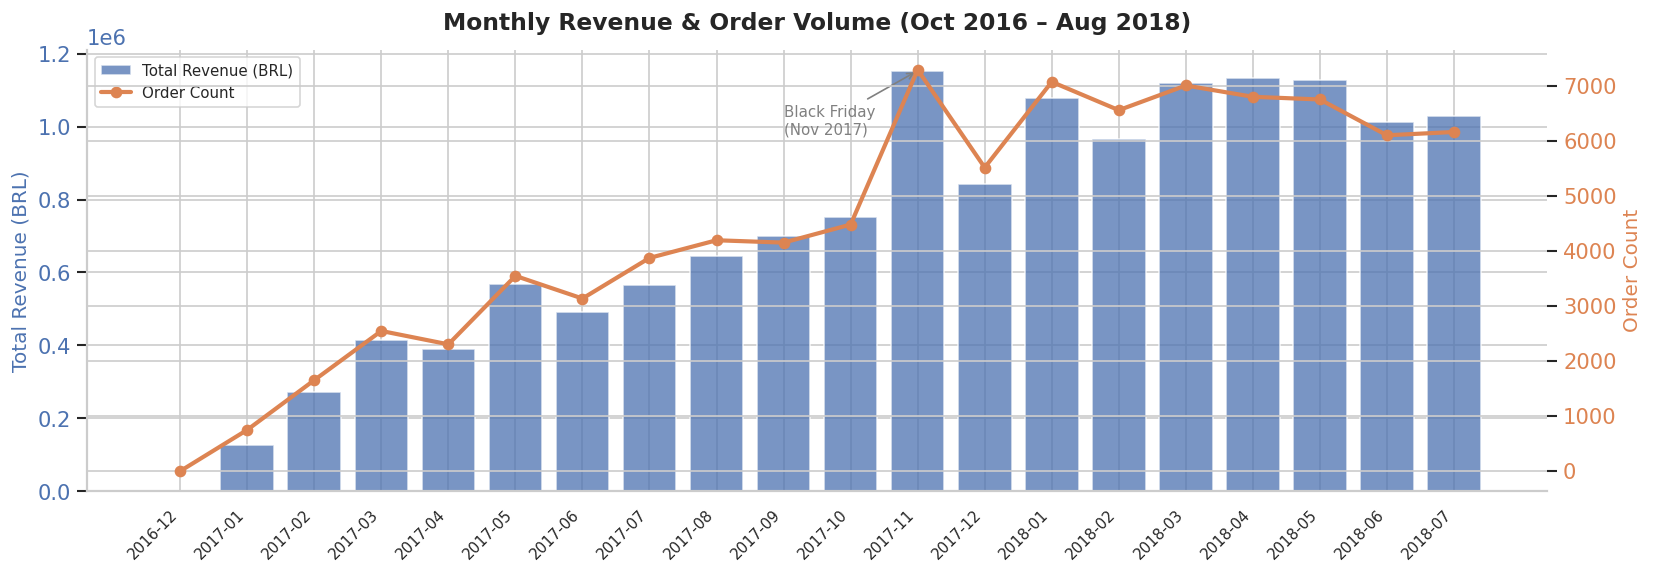

Saved: q1_monthly_trend.png


In [21]:
# ── Seaborn / Matplotlib — dual-axis static chart ──────────────────────────
x_labels = monthly_revenue['purchase_year_month'].astype(str)
x_pos    = list(range(len(x_labels)))
fig, ax1 = plt.subplots(figsize=(14, 5))

ax1.bar(
    x_pos, monthly_revenue['total_revenue'],
    color=BRAND_COLOR, 
    alpha=0.75, 
    label='Total Revenue (BRL)',
)
ax1.set_ylabel(
    'Total Revenue (BRL)', 
    color=BRAND_COLOR, 
    fontsize=12,
)
ax1.tick_params(
    axis='y', 
    labelcolor=BRAND_COLOR,
)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(
    x_labels, 
    rotation=45, 
    ha='right', 
    fontsize=9,
)
ax2 = ax1.twinx()
ax2.plot(
    x_pos, 
    monthly_revenue['orders'],
    color=ACCENT_COLOR, 
    marker='o', 
    linewidth=2.5, 
    label='Order Count',
)
ax2.set_ylabel(
    'Order Count', 
    color=ACCENT_COLOR, 
    fontsize=12,
)
ax2.tick_params(
    axis='y', 
    labelcolor=ACCENT_COLOR,
)
# Annotate Nov-2017 Black Friday spike
x_series = list(x_labels)
if '2017-11' in x_series:
    idx = x_series.index('2017-11')
    ax1.annotate(
        'Black Friday\n(Nov 2017)',
        xy=(idx, monthly_revenue['total_revenue'].iloc[idx]),
        xytext=(idx - 2, monthly_revenue['total_revenue'].max() * 0.85),
        arrowprops=dict(arrowstyle='->', color='gray'),
        fontsize=9, color='gray'
    )

lines1, lab1 = ax1.get_legend_handles_labels()
lines2, lab2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, lab1 + lab2, 
           loc='upper left', 
           fontsize=9,
)
ax1.set_title(
    'Monthly Revenue & Order Volume (Oct 2016 – Aug 2018)',
    fontsize=14, 
    fontweight='bold', 
    pad=12,
)
plt.tight_layout()
plt.savefig('dashboard/data/q1_monthly_trend.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: q1_monthly_trend.png')

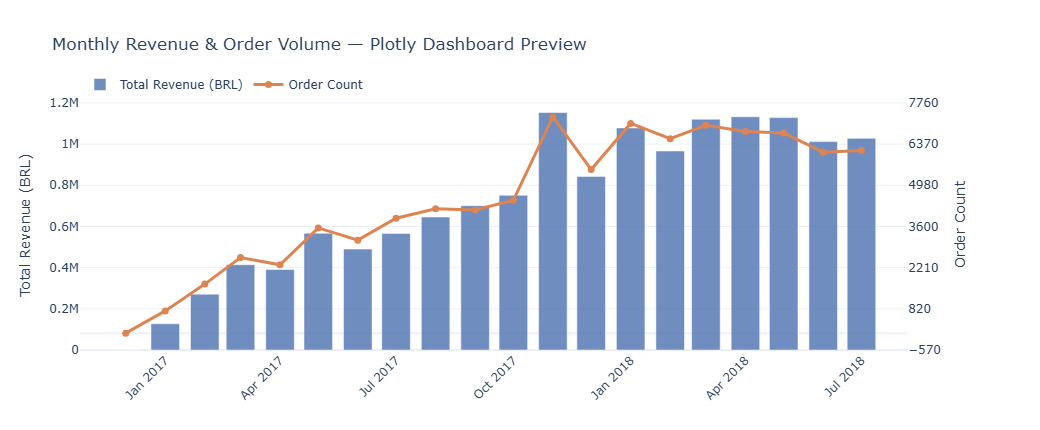

In [22]:
# ── Plotly — interactive dual-axis (Dashboard preview) ──────────────────────
mp = monthly_revenue.copy()
mp['month_str'] = mp['purchase_year_month'].astype(str)

fig_q1 = make_subplots(specs=[[{'secondary_y': True}]])
fig_q1.add_trace(
    go.Bar(x=mp['month_str'], 
           y=mp['total_revenue'],
           name='Total Revenue (BRL)', 
           marker_color=BRAND_COLOR, 
           opacity=0.8), secondary_y=False)

fig_q1.add_trace(
    go.Scatter(x=mp['month_str'], 
               y=mp['orders'],
               name='Order Count', 
               mode='lines+markers',
               line=dict(color=ACCENT_COLOR, width=3), 
               marker=dict(size=7)), secondary_y=True)

fig_q1.update_layout(
    title='Monthly Revenue & Order Volume — Plotly Dashboard Preview',
    template=PLOTLY_TEMPLATE, 
    legend=dict(orientation='h', y=1.12),
    height=430, 
    xaxis_tickangle=-45,
)
fig_q1.update_yaxes(title_text='Total Revenue (BRL)', secondary_y=False)
fig_q1.update_yaxes(title_text='Order Count',         secondary_y=True)
fig_q1.show()

In [23]:
# ── Insight summary ─────────────────────────────────────────────────────────
peak = monthly_revenue.loc[monthly_revenue['total_revenue'].idxmax()]
growth = (
    (monthly_revenue['total_revenue'].iloc[-1] -
     monthly_revenue['total_revenue'].iloc[0])
    / monthly_revenue['total_revenue'].iloc[0] * 100
)
print('=== Q1 Insights ===')
print(f"Peak month         : {peak['purchase_year_month']} -- "
      f"BRL {peak['total_revenue']:,.0f} ({peak['orders']:.0f} orders)")
print(f"Revenue growth     : {growth:.1f}% from Oct-2016 to Aug-2018")
print(f"Avg monthly orders : {monthly_revenue['orders'].mean():.0f}")
print(f"Avg order value    : BRL {monthly_revenue['avg_order_value'].mean():.2f}")

=== Q1 Insights ===
Peak month         : 2017-11 -- BRL 1,153,528 (7289 orders)
Revenue growth     : 5238961.5% from Oct-2016 to Aug-2018
Avg monthly orders : 4493
Avg order value    : BRL 153.88


---
### Q2 - Product Categories: Revenue vs Customer Satisfaction

**Question:** Which product categories generated the highest total revenue during October 2016 – August 2018, did the top-revenue categories achieve a mean review score of at least 4.0 out of 5, and which categories should be prioritised for quality or logistics intervention?

**Hypothesis:** Large/heavy items (furniture, appliances) earn high revenue
but suffer lower scores due to logistics friction.

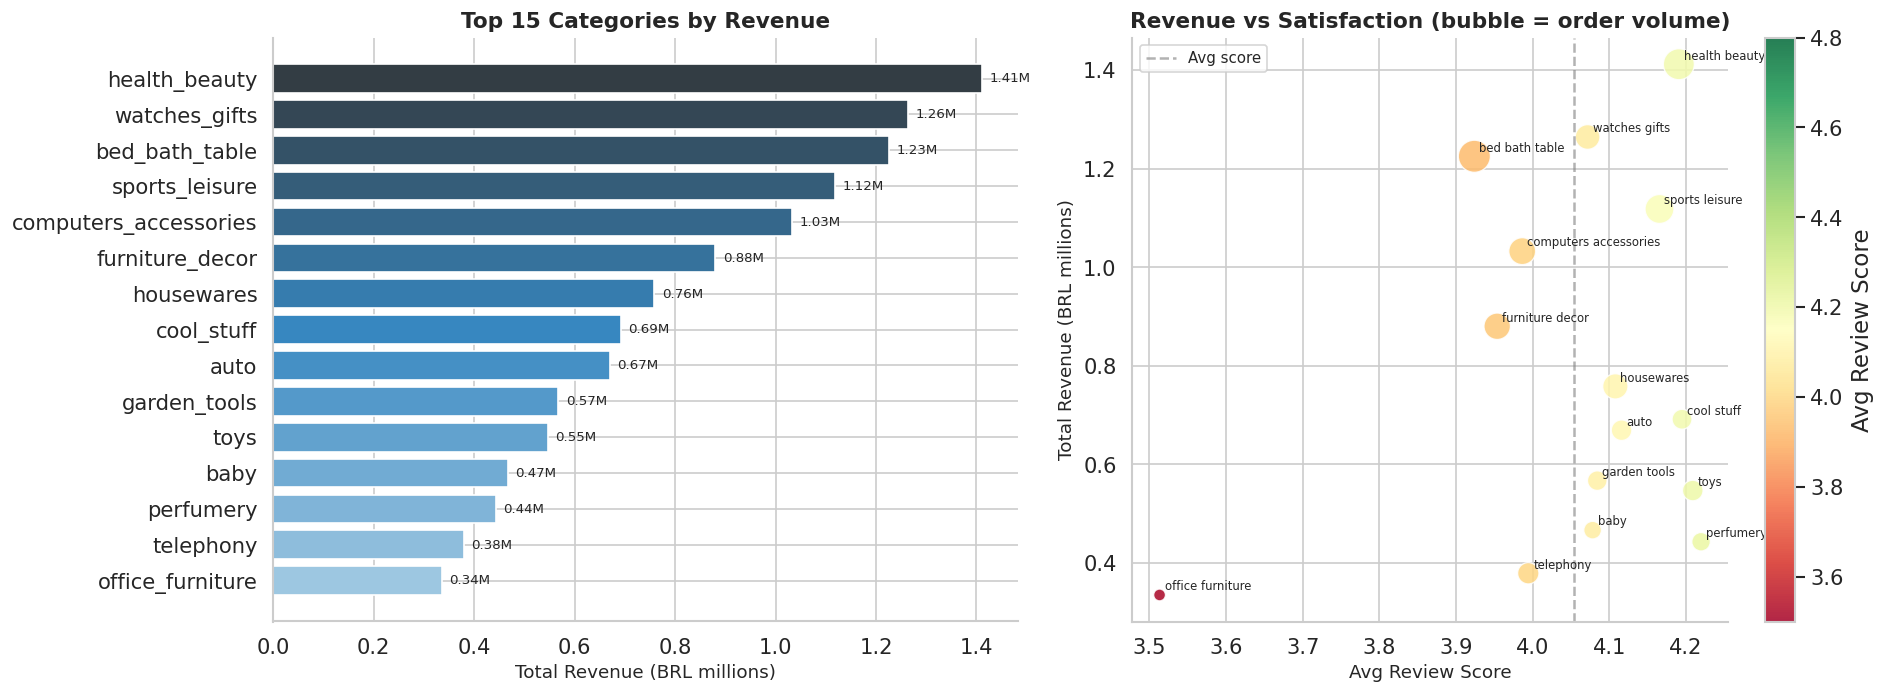

Saved: q2_category_revenue_vs_review.png


In [24]:
# ── Seaborn / Matplotlib — revenue bar + review score scatter ───────────────
top15 = category_stats.head(15).copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: horizontal revenue bar
pal = sns.color_palette('Blues_d', len(top15))
bars = axes[0].barh(
    top15['product_category_name'].iloc[::-1],
    top15['total_revenue'].iloc[::-1] / 1e6,
    color=pal,
)
for bar, val in zip(bars, top15['total_revenue'].iloc[::-1] / 1e6):
    axes[0].text(val + 0.015, 
                 bar.get_y() + bar.get_height() / 2,
                 f'{val:.2f}M', 
                 va='center', 
                 fontsize=8,
)    
axes[0].set_xlabel('Total Revenue (BRL millions)', fontsize=11)
axes[0].set_title('Top 15 Categories by Revenue', fontsize=13, fontweight='bold')

# Right: bubble — avg review vs revenue, sized by order count
sc = axes[1].scatter(
    top15['avg_review'], 
    top15['total_revenue'] / 1e6,
    s=top15['total_orders'] / 25, 
    c=top15['avg_review'],
    cmap='RdYlGn', 
    vmin=3.5, 
    vmax=4.8,
    alpha=0.85, 
    edgecolors='white', 
    linewidth=0.8,
)
plt.colorbar(
    sc, 
    ax=axes[1], 
    label='Avg Review Score',
)
for _, row in top15.iterrows():
    axes[1].annotate(
        row['product_category_name'].replace('_', ' '),
        (row['avg_review'], row['total_revenue'] / 1e6),
        fontsize=7, xytext=(3, 3), textcoords='offset points')
    
axes[1].axvline(
    top15['avg_review'].mean(), 
    color='gray',
    linestyle='--', 
    alpha=0.6, 
    label='Avg score',
)
axes[1].set_xlabel('Avg Review Score', fontsize=11)
axes[1].set_ylabel('Total Revenue (BRL millions)', fontsize=11)
axes[1].set_title('Revenue vs Satisfaction (bubble = order volume)', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('dashboard/data/q2_category_revenue_vs_review.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: q2_category_revenue_vs_review.png')

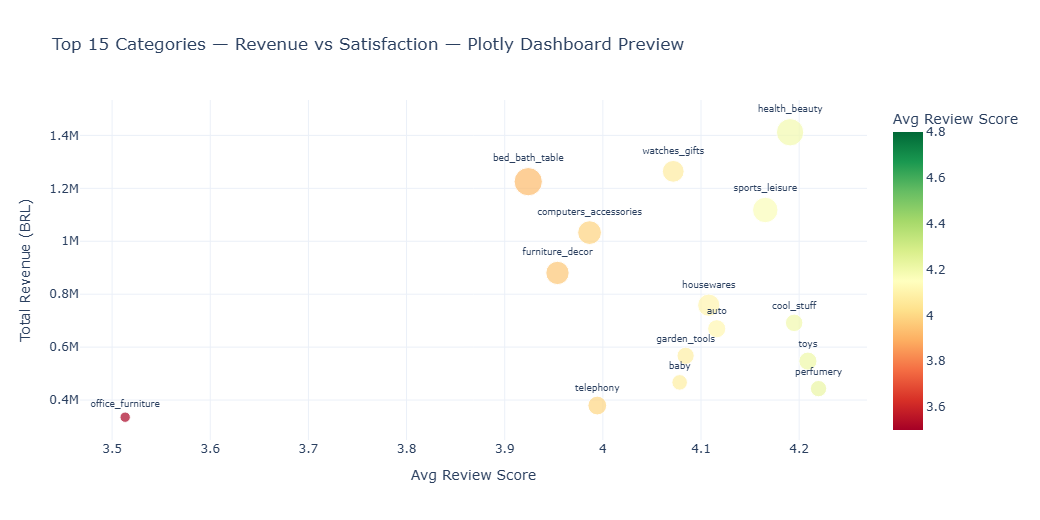

In [25]:
# ── Plotly — interactive bubble (Dashboard preview) ─────────────────────────
fig_q2 = px.scatter(
    top15,
    x='avg_review', 
    y='total_revenue',
    size='total_orders', 
    color='avg_review',
    text='product_category_name',
    color_continuous_scale='RdYlGn',
    range_color=[3.5, 4.8],
    labels={'avg_review': 'Avg Review Score',
            'total_revenue': 'Total Revenue (BRL)',
            'total_orders': 'Order Count',
            'product_category_name': 'Category'},
    title='Top 15 Categories — Revenue vs Satisfaction — Plotly Dashboard Preview',
    template=PLOTLY_TEMPLATE, height=520,
)
fig_q2.update_traces(textposition='top center', textfont_size=9)
fig_q2.show()

In [26]:
# ── Insight summary ─────────────────────────────────────────────────────────
print('=== Q2 Insights ===')
print('Top 5 by revenue:')
print(category_stats[['product_category_name','total_revenue','avg_review']].head().to_string(index=False))
print()
print('Top 5 by review score (min 500 orders):')
top_review = (category_stats[category_stats['total_orders'] >= 500].nlargest(5, 'avg_review')
    [['product_category_name','avg_review','total_revenue']]
)
print(top_review.to_string(index=False))
print()
print('Bottom 5 by review score (min 500 orders):')
bot_review = (category_stats[category_stats['total_orders'] >= 500].nsmallest(5, 'avg_review')
    [['product_category_name','avg_review','total_revenue']]
)
print(bot_review.to_string(index=False))

=== Q2 Insights ===
Top 5 by revenue:
product_category_name  total_revenue  avg_review
        health_beauty     1411946.07    4.190747
        watches_gifts     1264333.12    4.071711
       bed_bath_table     1225209.26    3.923968
       sports_leisure     1118256.91    4.165493
computers_accessories     1032723.77    3.986462

Top 5 by review score (min 500 orders):
product_category_name  avg_review  total_revenue
  luggage_accessories    4.352283      168778.12
           stationery    4.245818      269575.05
     small_appliances    4.225115      198108.47
      home_appliances    4.222148       93301.78
  musical_instruments    4.221705      202187.12

Bottom 5 by review score (min 500 orders):
product_category_name  avg_review  total_revenue
     office_furniture    3.513301      335211.36
       bed_bath_table    3.923968     1225209.26
              unknown    3.932450      203353.84
      furniture_decor    3.953775      880329.92
computers_accessories    3.986462     103272

---
### Q3 - Delivery Performance vs Customer Satisfaction

**Question:** How did late-delivery rate (%) and average delivery days differ across Brazilian states during October 2016 – August 2018, what was the review-score gap between late and on-time orders, and which states should be prioritised for logistics SLA enforcement?

**Hypothesis:** States far from São Paulo (the logistics hub) will have
higher late rates, which correlates with lower review scores.

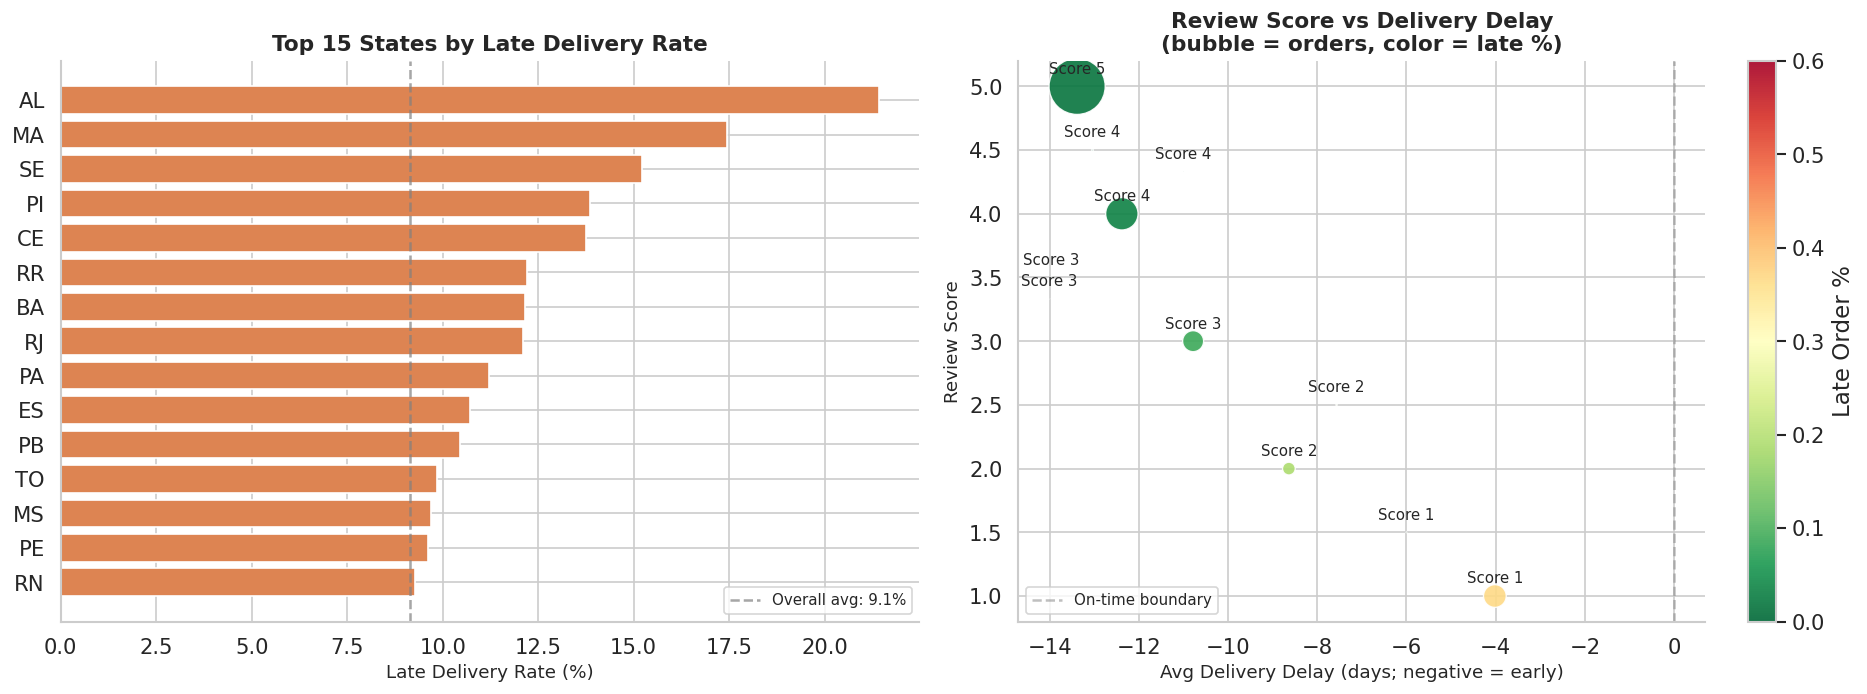

Saved: q3_delivery_vs_review.png


In [27]:
# ── Seaborn / Matplotlib — late rate bar + review vs delay scatter ──────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: late rate by state
top_late  = delivery_stats.head(15)
mean_late = delivery_stats['late_rate'].mean()
colors_l  = [ACCENT_COLOR if r > mean_late else BRAND_COLOR for r in top_late['late_rate']]

axes[0].barh(
    top_late['customer_state'].iloc[::-1],
    (top_late['late_rate'] * 100).iloc[::-1],
    color=colors_l[::-1],
)
axes[0].axvline(
    mean_late * 100, 
    color='gray', 
    linestyle='--', 
    alpha=0.7,
    label=f'Overall avg: {mean_late*100:.1f}%')

axes[0].set_xlabel('Late Delivery Rate (%)', fontsize=11)
axes[0].set_title('Top 15 States by Late Delivery Rate', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=9)

# Right: review score vs avg delay days
sc = axes[1].scatter(
    review_delivery['avg_delay_days'],
    review_delivery['review_score'],
    s=review_delivery['orders'] / 50,
    c=review_delivery['late_pct'],
    cmap='RdYlGn_r', 
    vmin=0, 
    vmax=0.6,
    alpha=0.9, 
    edgecolors='white', 
    linewidth=0.8,
)
plt.colorbar(sc, ax=axes[1], label='Late Order %')

for _, r in review_delivery.iterrows():
    axes[1].annotate(
        f'Score {int(r["review_score"])}',
        (r['avg_delay_days'], r['review_score']),
        fontsize=9, ha='center', va='bottom',
        xytext=(0, 6), textcoords='offset points',
)
axes[1].axvline(0, color='gray', linestyle='--', alpha=0.5, label='On-time boundary')
axes[1].set_xlabel('Avg Delivery Delay (days; negative = early)', fontsize=11)
axes[1].set_ylabel('Review Score', fontsize=11)
axes[1].set_title('Review Score vs Delivery Delay\n(bubble = orders, color = late %)', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('dashboard/data/q3_delivery_vs_review.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: q3_delivery_vs_review.png')

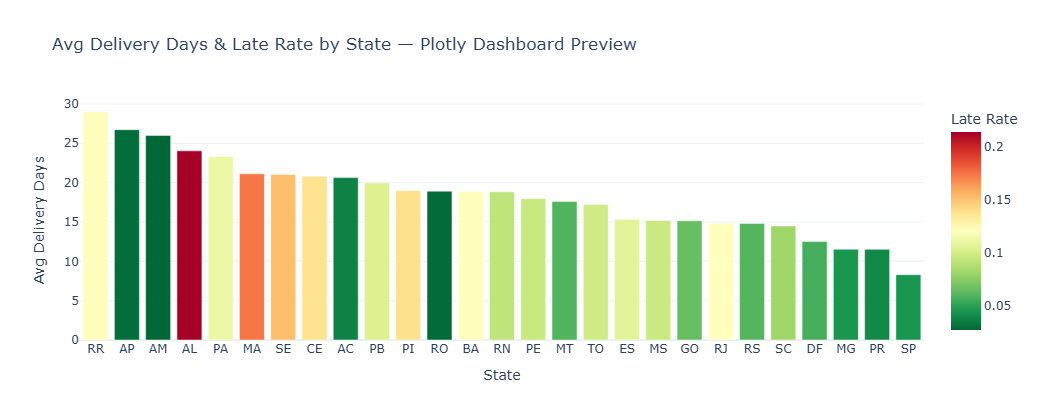

In [28]:
# ── Plotly — avg delivery days by state, coloured by late rate ──────────────
fig_q3a = px.bar(
    delivery_stats.sort_values('avg_delivery_days', ascending=False),
    x='customer_state', 
    y='avg_delivery_days',
    color='late_rate',
    color_continuous_scale='RdYlGn_r',
    labels={'customer_state': 'State',
            'avg_delivery_days': 'Avg Delivery Days',
            'late_rate': 'Late Rate'},
    title='Avg Delivery Days & Late Rate by State — Plotly Dashboard Preview',
    template=PLOTLY_TEMPLATE, height=420,
)
fig_q3a.show()

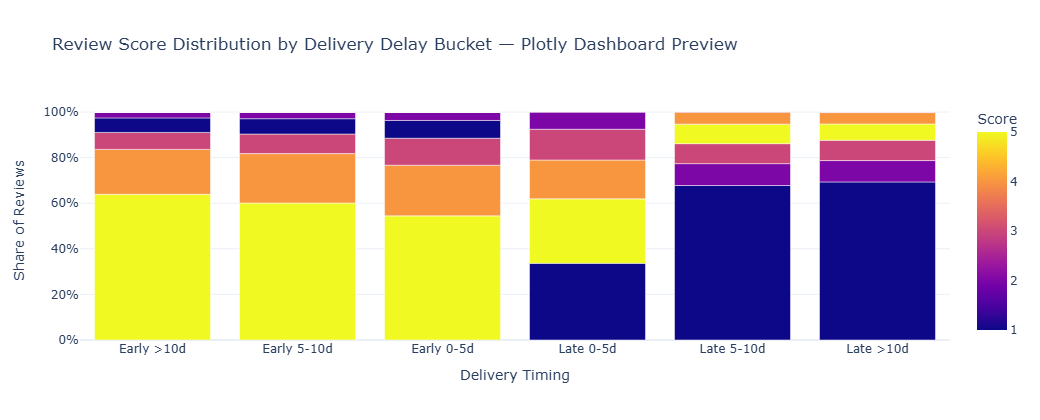

In [29]:
# ── Plotly — stacked bar: review score distribution by delay bucket ──────────
delay_df = (
    delivered_df
    .drop_duplicates(subset='order_id')
    .dropna(subset=['review_score', 'delivery_delay_days'])
    .copy()
)
bins   = [-999, -10, -5, 0, 5, 10, 999]
labels = ['Early >10d', 'Early 5-10d', 'Early 0-5d', 'Late 0-5d', 'Late 5-10d',  'Late >10d']
delay_df['delay_bucket'] = pd.cut(delay_df['delivery_delay_days'], bins=bins, labels=labels)
review_by_bucket = (
    delay_df
    .groupby('delay_bucket', observed=True)['review_score']
    .value_counts(normalize=True)
    .rename('pct')
    .reset_index()
)
fig_q3b = px.bar(
    review_by_bucket,
    x='delay_bucket', 
    y='pct', 
    color='review_score',
    barmode='stack',
    color_discrete_sequence=px.colors.diverging.RdBu,
    labels={'delay_bucket': 'Delivery Timing',
            'pct': 'Share of Reviews',
            'review_score': 'Score'},
    title='Review Score Distribution by Delivery Delay Bucket — Plotly Dashboard Preview',
    template=PLOTLY_TEMPLATE, height=420,
)
fig_q3b.update_layout(yaxis_tickformat='.0%')
fig_q3b.show()

In [30]:
# ── Insight summary ─────────────────────────────────────────────────────────
overall_late = delivery_stats['late_rate'].mean()
worst        = delivery_stats.iloc[0]
fastest      = delivery_stats.sort_values('avg_delivery_days').iloc[0]
# Use review_score directly: score 1-3 = dissatisfied, 4-5 = satisfied
low_scores  = review_delivery[review_delivery['review_score'] <= 3]
high_scores = review_delivery[review_delivery['review_score'] >= 4]
avg_delay_low  = low_scores['avg_delay_days'].mean()
avg_delay_high = high_scores['avg_delay_days'].mean()
# Weighted avg review by is_late flag (from delay_df built in viz-0303)
late_mask   = delay_df['delivery_delay_days'] > 0
score_late  = delay_df[late_mask]['review_score'].mean()
score_early = delay_df[~late_mask]['review_score'].mean()
print('=== Q3 Insights ===')
print(f'Overall late delivery rate     : {overall_late*100:.1f}%')
print(f'Worst state (late rate)        : {worst["customer_state"]}, '
      f'{worst["late_rate"]*100:.1f}% late, avg {worst["avg_delivery_days"]:.1f} days')
print(f'Fastest state                  : {fastest["customer_state"]}, '
      f'avg {fastest["avg_delivery_days"]:.1f} days')
print(f'Avg delay for score 1-3 orders : {avg_delay_low:.1f} days')
print(f'Avg delay for score 4-5 orders : {avg_delay_high:.1f} days')
print(f'Avg review (on-time/early)     : {score_early:.2f}')
print(f'Avg review (late orders)       : {score_late:.2f}')
print(f'Review score drop (late)       : {score_early - score_late:.2f} points')

=== Q3 Insights ===
Overall late delivery rate     : 9.1%
Worst state (late rate)        : AL, 21.4% late, avg 24.0 days
Fastest state                  : SP, avg 8.3 days
Avg delay for score 1-3 orders : -7.4 days
Avg delay for score 4-5 orders : -12.5 days
Avg review (on-time/early)     : 4.29
Avg review (late orders)       : 2.27
Review score drop (late)       : 2.02 points


---
### Q4 - Geographic Distribution of Customers & Revenue

**Question:** What share of customers and revenue was concentrated in each Brazilian state during October 2016 – August 2018, which states were under-served (< 1% revenue share), and where should seller recruitment and marketing spend be directed?

**Hypothesis:** São Paulo and Rio de Janeiro will dominate; northern states
will be significantly under-represented.

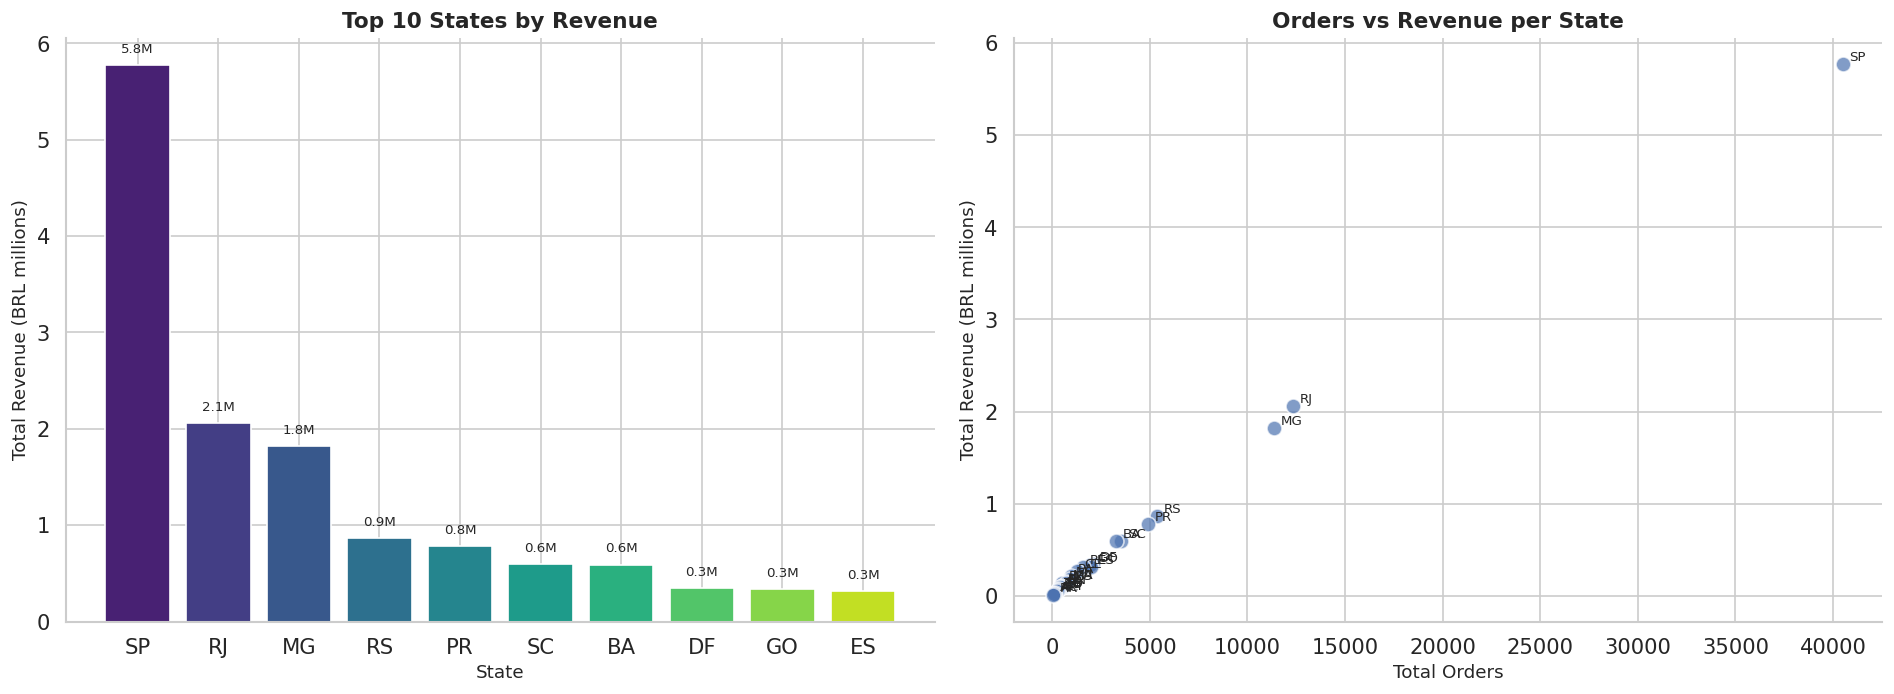

Saved: q4_geo_revenue.png


In [31]:
# ── Seaborn / Matplotlib — top states bar + all-states scatter ───────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top10s = state_revenue.head(10)
pal_s  = sns.color_palette('viridis', len(top10s))
bars   = axes[0].bar(top10s['customer_state'], top10s['total_revenue'] / 1e6, color=pal_s)

for bar, val in zip(bars, top10s['total_revenue'] / 1e6):
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 val + 0.1, f'{val:.1f}M',
                 ha='center', va='bottom', fontsize=8)
    
axes[0].set_xlabel('State', fontsize=11)
axes[0].set_ylabel('Total Revenue (BRL millions)', fontsize=11)
axes[0].set_title('Top 10 States by Revenue', fontsize=13, fontweight='bold')

axes[1].scatter(
    state_revenue['total_orders'],
    state_revenue['total_revenue'] / 1e6,
    s=80, 
    color=BRAND_COLOR, 
    alpha=0.7, 
    edgecolors='white',
)
for _, row in state_revenue.iterrows():
    axes[1].annotate(
        row['customer_state'],
        (row['total_orders'], row['total_revenue'] / 1e6),
        fontsize=8, 
        ha='left', 
        xytext=(4, 2), 
        textcoords='offset points',
)
axes[1].set_xlabel('Total Orders', fontsize=11)
axes[1].set_ylabel('Total Revenue (BRL millions)', fontsize=11)
axes[1].set_title('Orders vs Revenue per State', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('dashboard/data/q4_geo_revenue.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: q4_geo_revenue.png')

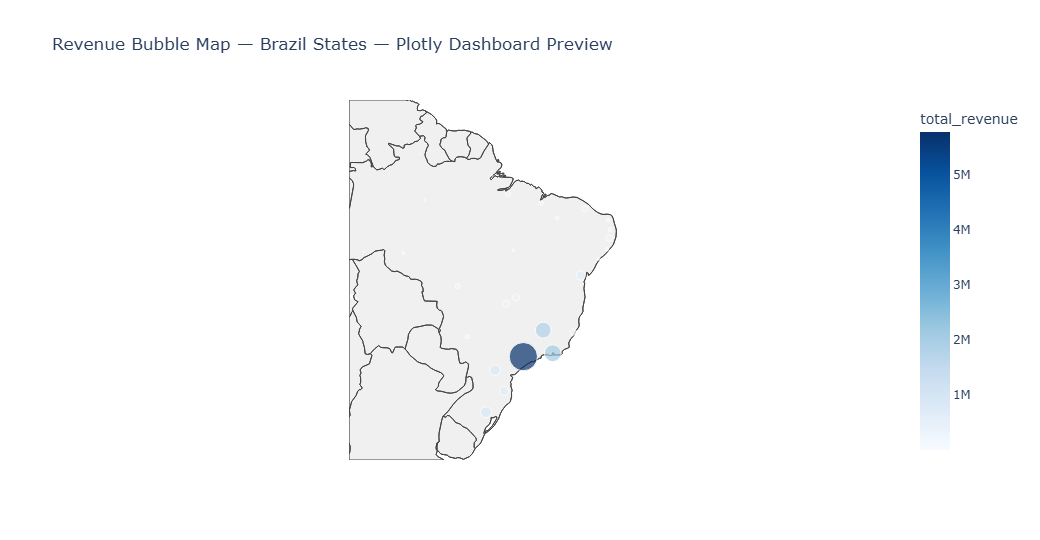

In [32]:
# ── Plotly — bubble map on Brazil (Dashboard preview) ───────────────────────
fig_q4 = px.scatter_geo(
    state_revenue,
    lat='avg_lat', lon='avg_lng',
    size='total_revenue',
    color='total_revenue',
    color_continuous_scale='Blues',
    hover_name='customer_state',
    hover_data={'total_orders': True, 'total_revenue': ':,.0f',
                'avg_lat': False, 'avg_lng': False},
    scope='south america',
    title='Revenue Bubble Map — Brazil States — Plotly Dashboard Preview',
    template=PLOTLY_TEMPLATE, height=540,
)
fig_q4.update_geos(fitbounds='locations', showland=True,
                   landcolor='#f0f0f0', showcoastlines=True)
fig_q4.show()

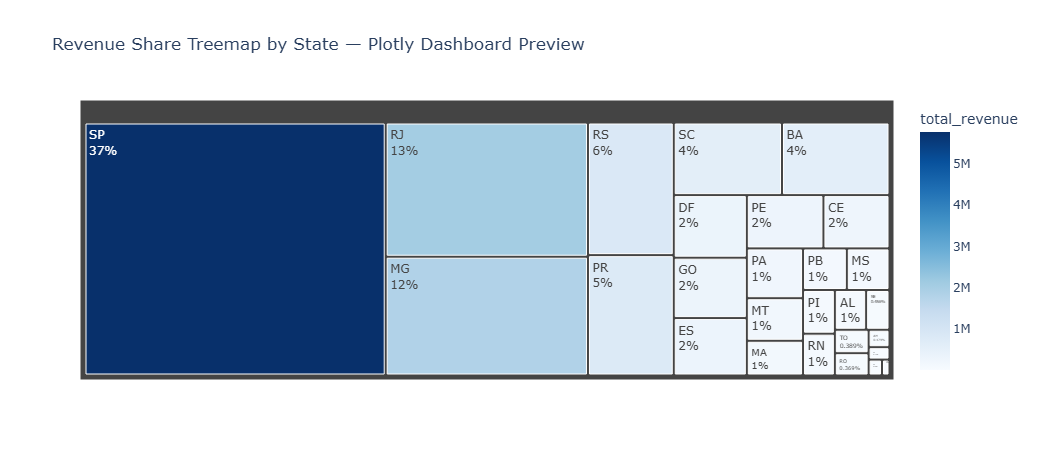

In [33]:
# ── Plotly — treemap of revenue share by state ──────────────────────────────
fig_q4b = px.treemap(
    state_revenue,
    path=['customer_state'],
    values='total_revenue',
    color='total_revenue',
    color_continuous_scale='Blues',
    title='Revenue Share Treemap by State — Plotly Dashboard Preview',
    template=PLOTLY_TEMPLATE, height=460,
)
fig_q4b.update_traces(textinfo='label+percent root')
fig_q4b.show()

In [34]:
# ── Insight summary ─────────────────────────────────────────────────────────
total_rev = state_revenue['total_revenue'].sum()
sp_share  = (
    state_revenue[state_revenue['customer_state'] == 'SP']['total_revenue'].values[0]
    / total_rev * 100
)
top3_share = state_revenue.head(3)['total_revenue'].sum() / total_rev * 100
total_cust    = state_revenue['total_customers'].sum()
sp_cust_share = (
    state_revenue[state_revenue['customer_state'] == 'SP']['total_customers'].values[0]
    / total_cust * 100
)

print('=== Q4 Insights ===')
print(f'SP revenue share           : {sp_share:.1f}%')
print(f'SP customer share          : {sp_cust_share:.1f}%')
print(f'Top 3 states revenue share : {top3_share:.1f}%')
print(f'States with < 1% share     : '
      f'{(state_revenue["total_revenue"] / total_rev < 0.01).sum()}')

print('\nTop 5 states:')
print(state_revenue[['customer_state','total_revenue','total_orders','total_customers']].head().to_string(index=False))

=== Q4 Insights ===
SP revenue share           : 37.4%
SP customer share          : 42.0%
Top 3 states revenue share : 62.5%
States with < 1% share     : 13

Top 5 states:
customer_state  total_revenue  total_orders  total_customers
            SP     5769559.69         40500            40500
            RJ     2055401.57         12350            12350
            MG     1818891.67         11354            11354
            RS      861472.79          5345             5345
            PR      781708.80          4923             4923


---
### Q5 - Payment Behaviour: Type Split & Installment Patterns

**Question:** What was the payment-type distribution by order volume during October 2016 – August 2018, how much larger was the average spend of customers paying in 12 installments vs. 1 installment, and should installment financing be expanded at checkout?

**Hypothesis:** Credit cards dominate; customers splitting into more
installments finance larger purchases (higher total spend).

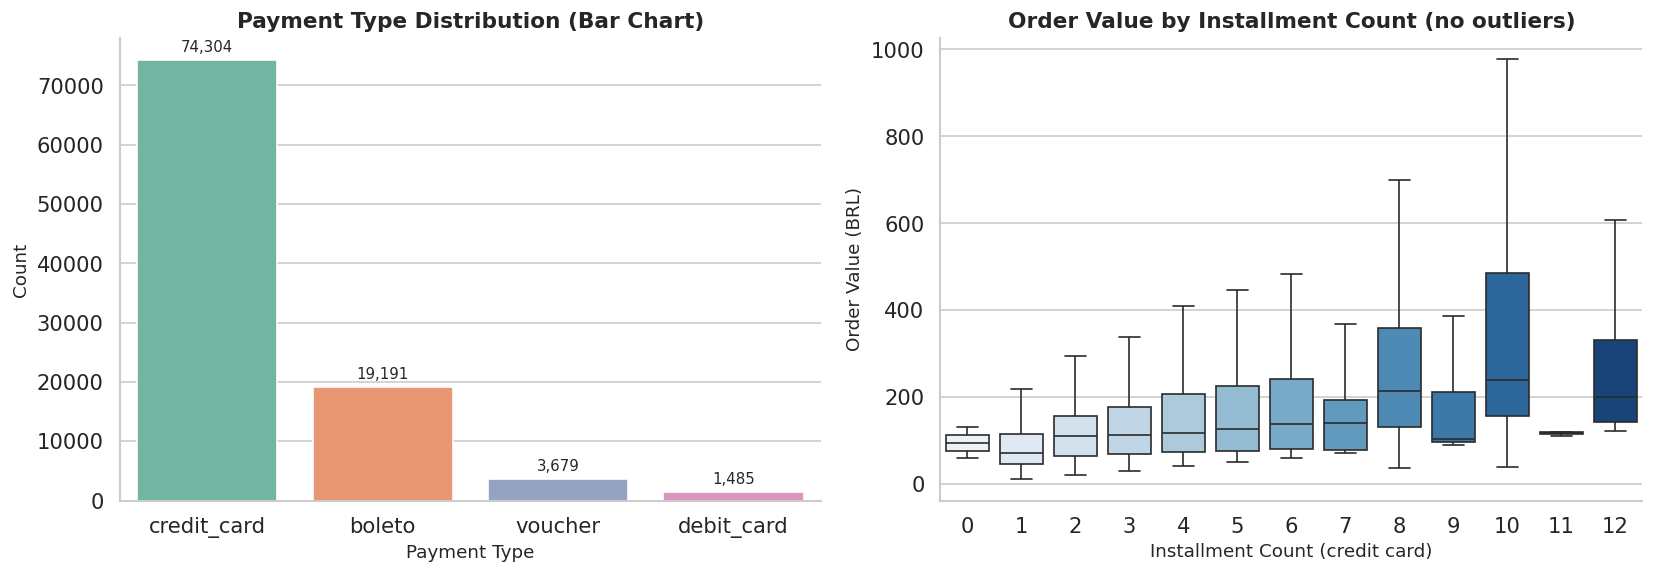

Saved: q5_payment_behaviour.png


In [35]:
# ── Seaborn / Matplotlib — donut chart + installment boxplot ────────────────
pay_type = (
    delivered_df
    .drop_duplicates(subset='order_id')
    .copy()
)
pay_expanded = (
    pay_type['payment_types']
    .str.split(', ').explode()
    .value_counts()
    .reset_index()
)
pay_expanded.columns = ['payment_type', 'count']

cc_df = pay_type[
    (pay_type['payment_types'] == 'credit_card') &
    (pay_type['payment_installments'] <= 12)
].copy()
cc_df['payment_installments'] = cc_df['payment_installments'].astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=pay_expanded,
    x='payment_type',
    y='count',
    palette='Set2',
    ax=axes[0],
)

# Add value labels above each bar
for p in axes[0].patches:
    height = p.get_height()
    axes[0].annotate(
        f'{height:,.0f}',
        (p.get_x() + p.get_width() / 2., height),
        ha='center', 
        va='bottom',
        fontsize=9, 
        xytext=(0, 3),
        textcoords='offset points',
)
axes[0].set_xlabel('Payment Type', fontsize=11)
axes[0].set_ylabel('Count', fontsize=11)
axes[0].set_title('Payment Type Distribution (Bar Chart)', fontsize=13, fontweight='bold')
axes[0].tick_params(axis='x') #rotation=15)

sns.boxplot(
    data=cc_df, 
    x='payment_installments', 
    y='payment_total_value',
    palette='Blues', 
    showfliers=False, 
    ax=axes[1],
)
axes[1].set_xlabel('Installment Count (credit card)', fontsize=11)
axes[1].set_ylabel('Order Value (BRL)', fontsize=11)
axes[1].set_title('Order Value by Installment Count (no outliers)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('dashboard/data/q5_payment_behaviour.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: q5_payment_behaviour.png')

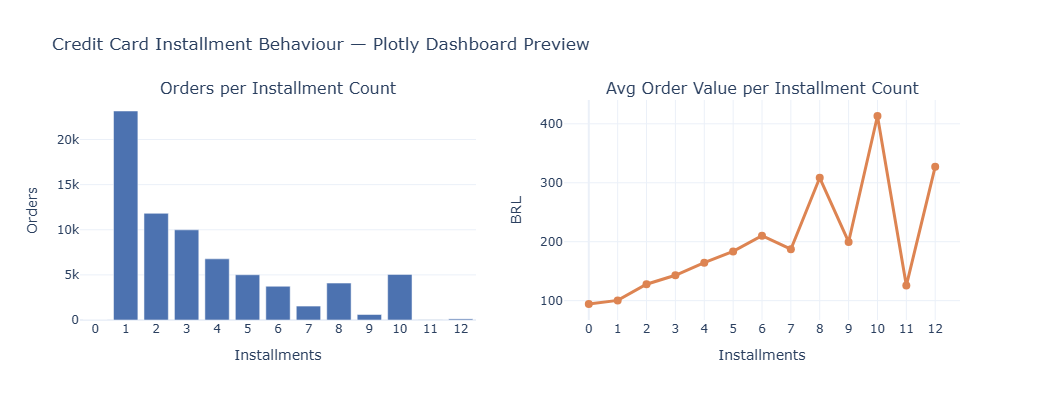

In [36]:
# ── Plotly — installment count bar + avg order value line ───────────────────
inst_sum = (
    cc_df.groupby('payment_installments', as_index=False)
         .agg(order_count=('order_id', 'nunique'),
              avg_value  =('payment_total_value', 'mean'))
)
fig_q5 = make_subplots(
    rows=1, 
    cols=2,
    subplot_titles=('Orders per Installment Count',
                    'Avg Order Value per Installment Count')
)
fig_q5.add_trace(
    go.Bar(
        x=inst_sum['payment_installments'], 
        y=inst_sum['order_count'],
        marker_color=BRAND_COLOR, 
        name='Order Count'),
    row=1, 
    col=1,
)
fig_q5.add_trace(
    go.Scatter(
        x=inst_sum['payment_installments'], 
        y=inst_sum['avg_value'],
        mode='lines+markers',
        line=dict(color=ACCENT_COLOR, width=3), marker=dict(size=8),
        name='Avg Order Value (BRL)'),
    row=1, 
    col=2,
)
fig_q5.update_layout(
    title_text='Credit Card Installment Behaviour — Plotly Dashboard Preview',
    template=PLOTLY_TEMPLATE, 
    height=400, 
    showlegend=False,
)
fig_q5.update_xaxes(title_text='Installments', dtick=1)
fig_q5.update_yaxes(title_text='Orders', row=1, col=1)
fig_q5.update_yaxes(title_text='BRL', row=1, col=2)
fig_q5.show()

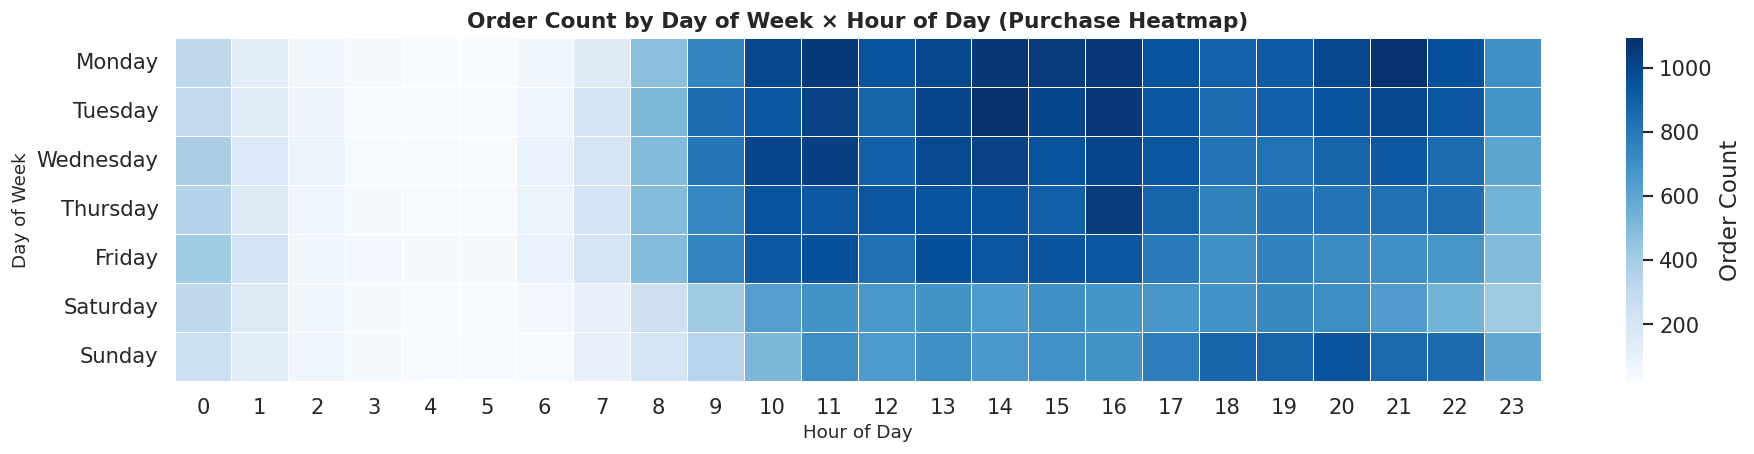

Saved: q5_purchase_heatmap.png


In [37]:
# ── Seaborn — purchase hour × day-of-week heatmap (bonus Q) ─────────────────
hour_dow = (
    delivered_df
    .drop_duplicates(subset='order_id')
    .groupby(['purchase_dow', 'purchase_hour'])['order_id']
    .nunique()
    .unstack(fill_value=0)
)
dow_order = ['Monday','Tuesday','Wednesday','Thursday','Friday',
             'Saturday','Sunday']

hour_dow  = hour_dow.reindex(dow_order)
fig, ax   = plt.subplots(figsize=(16, 4))
sns.heatmap(
    hour_dow, 
    cmap='Blues', 
    linewidths=0.3,
    cbar_kws={'label': 'Order Count'}, 
    ax=ax,
)
ax.set_title('Order Count by Day of Week × Hour of Day (Purchase Heatmap)', fontsize=13, fontweight='bold')
ax.set_xlabel('Hour of Day', fontsize=11)
ax.set_ylabel('Day of Week', fontsize=11)
plt.tight_layout()
plt.savefig('dashboard/data/q5_purchase_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: q5_purchase_heatmap.png')

In [38]:
# ── Insight summary ─────────────────────────────────────────────────────────
cc_share   = (
    pay_expanded[pay_expanded['payment_type'] == 'credit_card']['count'].values[0]
    / pay_expanded['count'].sum() * 100
)
avg_val_1  = cc_df[cc_df['payment_installments'] == 1]['payment_total_value'].mean()
avg_val_12 = cc_df[cc_df['payment_installments'] == 12]['payment_total_value'].mean()
peak_hour  = (
    delivered_df
    .drop_duplicates(subset='order_id')
    .groupby('purchase_hour')['order_id'].nunique()
    .idxmax()
)
print('=== Q5 Insights ===')
print(f'Credit card share            : {cc_share:.1f}%')
print(f'Avg order value (1 install)  : BRL {avg_val_1:.2f}')
print(f'Avg order value (12 install) : BRL {avg_val_12:.2f}')
print(f'Spend multiplier (1 vs 12)   : {avg_val_12/avg_val_1:.1f}x')
print(f'Peak purchase hour           : {peak_hour}:00')

=== Q5 Insights ===
Credit card share            : 75.3%
Avg order value (1 install)  : BRL 100.41
Avg order value (12 install) : BRL 327.27
Spend multiplier (1 vs 12)   : 3.3x
Peak purchase hour           : 16:00


---
## Analysis Strategy

### Cohort vs RFM Feasibility

In [39]:
# ══════════════════════════════════════════════════════════════════════
# Part A
# Computes: unique customers, repeat buyers, date span
# (Cohort retention rates are added in Part B, after Step 18)
# ══════════════════════════════════════════════════════════════════════

customers_df = dfs['customers_dataset.csv']
orders_df_raw = dfs['orders_dataset.csv']   # raw, before cleaning

# ── Unique customers ─────────────────────────────────────────────────
n_unique = customers_df['customer_unique_id'].nunique()

# ── Repeat purchasers: orders per unique customer ─────────────────────
orders_per_customer = (
    orders_df_raw
    .merge(customers_df[['customer_id', 'customer_unique_id']],
           on='customer_id')
    .groupby('customer_unique_id')['order_id']
    .nunique()
)
n_2plus   = (orders_per_customer >= 2).sum()
n_3plus   = (orders_per_customer >= 3).sum()
pct_2plus = n_2plus / len(orders_per_customer) * 100
pct_3plus = n_3plus / len(orders_per_customer) * 100

# ── Data span ─────────────────────────────────────────────────────────
purchase_ts = pd.to_datetime(orders_df_raw['order_purchase_timestamp'],
                              errors='coerce')
date_min = purchase_ts.min().strftime('%b %Y')
date_max = purchase_ts.max().strftime('%b %Y')
n_months = (
    (purchase_ts.max().to_period('M') -
     purchase_ts.min().to_period('M')).n + 1
)

# ── Print ─────────────────────────────────────────────────────────────
print('=' * 62)
print('Part A (customer & order counts)')
print('=' * 62)
print(f'Unique customers (customer_unique_id)  : {n_unique:,}')
print(f'Total unique customers in orders table : {len(orders_per_customer):,}')
print(f'Customers with 2+ orders               : {n_2plus:,} ({pct_2plus:.1f}%)')
print(f'Customers with 3+ orders               : {n_3plus:,} ({pct_3plus:.1f}%)')
print(f'Data span                              : {date_min} - {date_max}')
print(f'Number of calendar months in dataset   : {n_months}')
print()
print('Order frequency distribution (unique customers):')
freq = orders_per_customer.value_counts().sort_index().head(10)
freq_pct = (freq / len(orders_per_customer) * 100).round(2)
freq_table = freq.to_frame('count').join(freq_pct.to_frame('pct_%'))
print(freq_table.to_string())
print()
print('> Cohort retention rates are printed in Part B (after Step 18).')

Part A (customer & order counts)
Unique customers (customer_unique_id)  : 96,096
Total unique customers in orders table : 96,096
Customers with 2+ orders               : 2,997 (3.1%)
Customers with 3+ orders               : 252 (0.3%)
Data span                              : Sep 2016 - Oct 2018
Number of calendar months in dataset   : 26

Order frequency distribution (unique customers):
          count  pct_%
order_id              
1         93099  96.88
2          2745   2.86
3           203   0.21
4            30   0.03
5             8   0.01
6             6   0.01
7             3   0.00
9             1   0.00
17            1   0.00

> Cohort retention rates are printed in Part B (after Step 18).



> All metrics below are computed and printed by the two **Feasibility Proof** code
> cells: **Part A** (directly above) for customer/order counts and data span,
> and **Part B** (directly after Step 18 — Cohort Retention) for retention rates.

| Metric | Computed Value | Implication |
|---|---|---|
| Unique customers (`customer_unique_id`) | **96,096** | Large enough for meaningful segmentation |
| Customers with 2+ orders | **2,997 (3.1%)** | Very low repeat rate — typical for B2C marketplaces |
| Customers with 3+ orders | **252 (0.3%)** | Negligible multi-purchase segment |
| Data span | **Sep 2016--Oct 2018** | ~26 calendar months, 22 usable monthly cohorts |
| Avg Month-1 cohort retention | **~0.44%** (mature cohorts) | Confirms one-time purchase pattern |
| Avg Month-6 cohort retention | **~0.18%** (mature cohorts) | No meaningful retention loop exists |

**RFM** - Works well even when Frequency ≈ 1 for 97% of customers.
Recency and Monetary scores differentiate high-value **Champions**
(avg BRL 312, last purchase within 91 days) from **Lost** customers
(avg BRL 55, silent for 475 days). All 7 segments are actionable.

**Cohort retention** - Works, but actual Month-1 retention is **~0.4--0.7%**
for mature cohorts. The heatmap still
delivers a key strategic insight: the one-time purchase pattern is structural,
not a temporary product issue, and it affects every cohort uniformly.

**Additional high-value analyses performed:**
1. Monthly revenue trend & order volume (**Q1**)
2. Top product categories by revenue and review score (**Q2**)
3. Delivery performance by state -- late rate and avg delivery days (**Q3**)
4. Customer geography -- revenue concentration by state (**Q4**)
5. Payment behaviour -- type split and installment patterns (**Q5**)

<br>

### Step 17 -- RFM Segmentation

In [40]:
from src.rfm import RFMAnalyzer

# Build entity-level RFM metrics + ordinal scores via the reusable module.
#   order_col   -> deduplicates to one row per order before aggregation
#   snapshot    -> defaults to max purchase timestamp + 1 day
#   frequency   -> nunique(order_id); heavy ties fall back to rank-binning
rfm_analyzer = RFMAnalyzer(
    delivered_df,
    entity_col="customer_unique_id",
    time_col="order_purchase_timestamp",
    value_col="payment_total_value",
    order_col="order_id",
    quantiles=5,
)

# scores + named 'segment' column; reset_index restores customer_unique_id
# as a regular column for downstream groupbys and the parquet export.
rfm = rfm_analyzer.segment().reset_index()

print('RFM shape:', rfm.shape)
print('\nSegment distribution:')
print(rfm['segment'].value_counts())
print('\nRFM summary by segment:')
print(rfm_analyzer.summary_by_segment().round(1))
print()
rfm.describe()

RFM shape: (93357, 10)

Segment distribution:
segment
Loyal Customers        27292
At Risk                22229
Recent Customers       14984
Potential Loyalists    10480
Cant Lose Them          8671
Champions               6493
Lost                    3208
Name: count, dtype: int64

RFM summary by segment:
                     customers  avg_recency  avg_frequency  avg_monetary  \
segment                                                                    
Champions                 6493         91.1            1.2         312.1   
Cant Lose Them            8671        394.6            1.0         241.0   
At Risk                  22229        394.6            1.0         167.0   
Recent Customers         14984         90.9            1.0         163.4   
Loyal Customers          27292        144.2            1.0         134.0   
Potential Loyalists      10480        248.8            1.0         125.1   
Lost                      3208        474.7            1.0          55.3   

       

,recency,frequency,monetary,R,F,M,RFM_score
count,93357.000000,93357.000000,93357.000000,93357.0,93357.0,93357.0,93357.0
mean,237.936673,1.033420,165.198772,3.003299,3.0,2.999807,9.003106
std,152.584315,0.209099,226.314579,1.414338,1.414236,1.414251,2.499079
min,1.000000,1.000000,9.590000,1.0,1.0,1.0,3.0
25%,114.000000,1.000000,63.060000,2.0,2.0,2.0,7.0
50%,219.000000,1.000000,107.780000,3.0,3.0,3.0,9.0
75%,346.000000,1.000000,182.560000,4.0,4.0,4.0,11.0
max,695.000000,15.000000,13664.080000,5.0,5.0,5.0,15.0


In [41]:
rfm.head()

,customer_unique_id,recency,frequency,monetary,R,F,M,RFM_profile,RFM_score,segment
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90,4,1,4,414,9,Recent Customers
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19,4,1,1,411,6,Recent Customers
2,0000f46a3911fa3c0805444483337064,537,1,86.22,1,1,2,112,4,Lost
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62,2,1,1,211,4,Potential Loyalists
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89,2,1,4,214,7,Cant Lose Them


---
### Step 18 -- Cohort Retention Analysis

In [42]:
from src.cohort import CohortAnalyzer

# Build the cohort analysis object. The module handles schema validation,
# datetime parsing, order-level consistency checks, deduplication, and
# cohort/period assignment -- for ANY event-level DataFrame.
cohort = CohortAnalyzer(
    delivered_df,
    customer_col="customer_unique_id",
    time_col="order_purchase_timestamp",
    order_col="order_id",
    freq="M",
    min_cohort_size=50,
)

# Aliases kept for downstream cells and the parquet export step
cohort_base         = cohort.base
cohort_counts       = cohort.counts
retention           = cohort.retention
eligible_counts     = cohort.eligible_counts
eligible_retention  = cohort.eligible_retention
max_observed_month  = cohort.max_observed_period
MIN_COHORT_SIZE     = cohort.min_cohort_size
eligible_cohorts    = cohort.eligible_counts.index

# Basic dataset diagnostics
s = cohort.summary()
print('COHORT BASE — DATA QUALITY CHECK')
print('=' * 55)
print(f'Total orders    : {cohort_base["order_id"].nunique():,}')
print(f'Total customers : {s.n_entities:,}')
print(f'Date range      : {s.date_min}')
print(f'                  {s.date_max}')
print(f'Duplicate orders: {cohort_base["order_id"].duplicated().sum():,}')
print(f'Missing values  : {cohort_base[["order_id","customer_unique_id","order_purchase_timestamp"]].isna().sum().sum():,}')

COHORT BASE — DATA QUALITY CHECK
Total orders    : 96,477
Total customers : 93,357
Date range      : 2016-10-03 09:44:50
                  2018-08-29 15:00:37
Duplicate orders: 0
Missing values  : 0


<br>

#### Cohort Construction

In [43]:
# Cohort construction is handled inside CohortAnalyzer:
#   order_period  = event timestamp floored to freq ('M')
#   cohort_period = each entity's first-ever order_period
#   period_index  = order_period - cohort_period  (in periods)
cohort_base[[
    'customer_unique_id', 'order_purchase_timestamp',
    'order_period', 'cohort_period', 'period_index'
]].head(10)

,customer_unique_id,order_purchase_timestamp,order_period,cohort_period,period_index
0,32ea3bdedab835c3aa6cb68ce66565ef,2016-10-03 09:44:50,2016-10,2016-10,0
1,2f64e403852e6893ae37485d5fcacdaf,2016-10-03 16:56:50,2016-10,2016-10,0
2,61db744d2f835035a5625b59350c6b63,2016-10-03 21:13:36,2016-10,2016-10,0
3,8d3a54507421dbd2ce0a1d58046826e0,2016-10-03 22:06:03,2016-10,2016-10,0
4,87776adb449c551e74c13fc34f036105,2016-10-03 22:31:31,2016-10,2016-10,0
5,7390ed59fa1febbfda31a80b4318c8cb,2016-10-03 22:44:10,2016-10,2016-10,0
6,10e89fd8e5c745f81bec101207ba4d7d,2016-10-03 22:51:30,2016-10,2016-10,0
7,cd5a5843d35eebdf90368bf24d4a04cf,2016-10-04 09:06:10,2016-10,2016-10,0
8,14359ea0c7a105749c0a56478825b015,2016-10-04 09:16:33,2016-10,2016-10,0
9,88bc832f104b6dd684a17dbb1b76e778,2016-10-04 09:59:03,2016-10,2016-10,0


<br>

#### Cohort Count Matrix & Retention Calculation

In [44]:
# cohort_counts / retention were built by CohortAnalyzer (see cell above).
# Display versions use a 1-based period index and timestamp cohort labels
# for readability; the underlying matrices stay 0-based with Period index.
cohort_counts_display = cohort_counts.copy()
retention_display = retention.copy()

cohort_counts_display.index = cohort_counts_display.index.to_timestamp()
retention_display.index = retention_display.index.to_timestamp()
cohort_counts_display.columns += 1
retention_display.columns += 1

cohort_counts_display.index.name = 'CohortMonth'
cohort_counts_display.columns.name = 'CohortIndex'
retention_display.index.name = 'CohortMonth'
retention_display.columns.name = 'CohortIndex'

print('COHORT COUNTS MATRIX')
print('=' * 33)
display(cohort_counts_display)

print('\nRETENTION RATES (%)')
print('=' * 33)
display((retention_display * 100).round(2))

COHORT COUNTS MATRIX


CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21
CohortMonth,,,,,,,,,,,,,,,,,,,,,
2016-10-01,262,0,0,0,0,0,1,0,0,1,0,1,0,1,0,1,0,1,0,2,2
2016-12-01,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2017-01-01,717,2,2,1,3,1,3,1,1,0,3,1,5,3,1,1,2,3,0,1,<NA>
2017-02-01,1628,3,5,2,7,2,4,3,2,3,2,5,2,3,2,1,1,3,0,<NA>,<NA>
2017-03-01,2503,11,9,10,9,4,4,8,8,2,9,3,5,3,4,6,2,3,<NA>,<NA>,<NA>
2017-04-01,2256,14,5,4,6,6,8,7,7,4,6,2,1,1,2,2,3,<NA>,<NA>,<NA>,<NA>
2017-05-01,3451,16,16,10,10,11,14,5,9,9,9,12,8,1,6,7,<NA>,<NA>,<NA>,<NA>,<NA>
2017-06-01,3037,15,12,13,9,12,11,7,4,6,9,11,5,5,7,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2017-07-01,3752,20,13,9,11,8,12,4,7,10,8,11,5,9,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>



RETENTION RATES (%)


CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21
CohortMonth,,,,,,,,,,,,,,,,,,,,,
2016-10-01,100.0,0.0,0.0,0.0,0.0,0.0,0.38,0.0,0.0,0.38,0.0,0.38,0.0,0.38,0.0,0.38,0.0,0.38,0.0,0.76,0.76
2016-12-01,100.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2017-01-01,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,0.0,0.42,0.14,0.7,0.42,0.14,0.14,0.28,0.42,0.0,0.14,<NA>
2017-02-01,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12,0.18,0.12,0.06,0.06,0.18,0.0,<NA>,<NA>
2017-03-01,100.0,0.44,0.36,0.4,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.2,0.12,0.16,0.24,0.08,0.12,<NA>,<NA>,<NA>
2017-04-01,100.0,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04,0.04,0.09,0.09,0.13,<NA>,<NA>,<NA>,<NA>
2017-05-01,100.0,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23,0.03,0.17,0.2,<NA>,<NA>,<NA>,<NA>,<NA>
2017-06-01,100.0,0.49,0.4,0.43,0.3,0.4,0.36,0.23,0.13,0.2,0.3,0.36,0.16,0.16,0.23,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2017-07-01,100.0,0.53,0.35,0.24,0.29,0.21,0.32,0.11,0.19,0.27,0.21,0.29,0.13,0.24,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


<br>

#### Retention Diagnostics

In [45]:
# Retention diagnostics over eligible cohorts (>= MIN_COHORT_SIZE at
# acquisition), computed by CohortAnalyzer.diagnostics()
retention_diagnostics = cohort.diagnostics(periods=[1, 3, 6])

print('COHORT RETENTION DIAGNOSTICS')
print('=' * 85)
print(f'Eligible cohorts: {cohort.eligible_counts.shape[0]}')
print(retention_diagnostics.round(2).to_string())

COHORT RETENTION DIAGNOSTICS
Eligible cohorts: 21
          Observed Cohorts  Macro Retention (%)  Weighted Retention (%)  Best Cohort (%)
Period                                                                                  
Period-1                20                 0.45                    0.48             0.72
Period-3                18                 0.24                    0.25             0.43
Period-6                15                 0.27                    0.23             0.42


<br>

#### Cohort Retention Curve

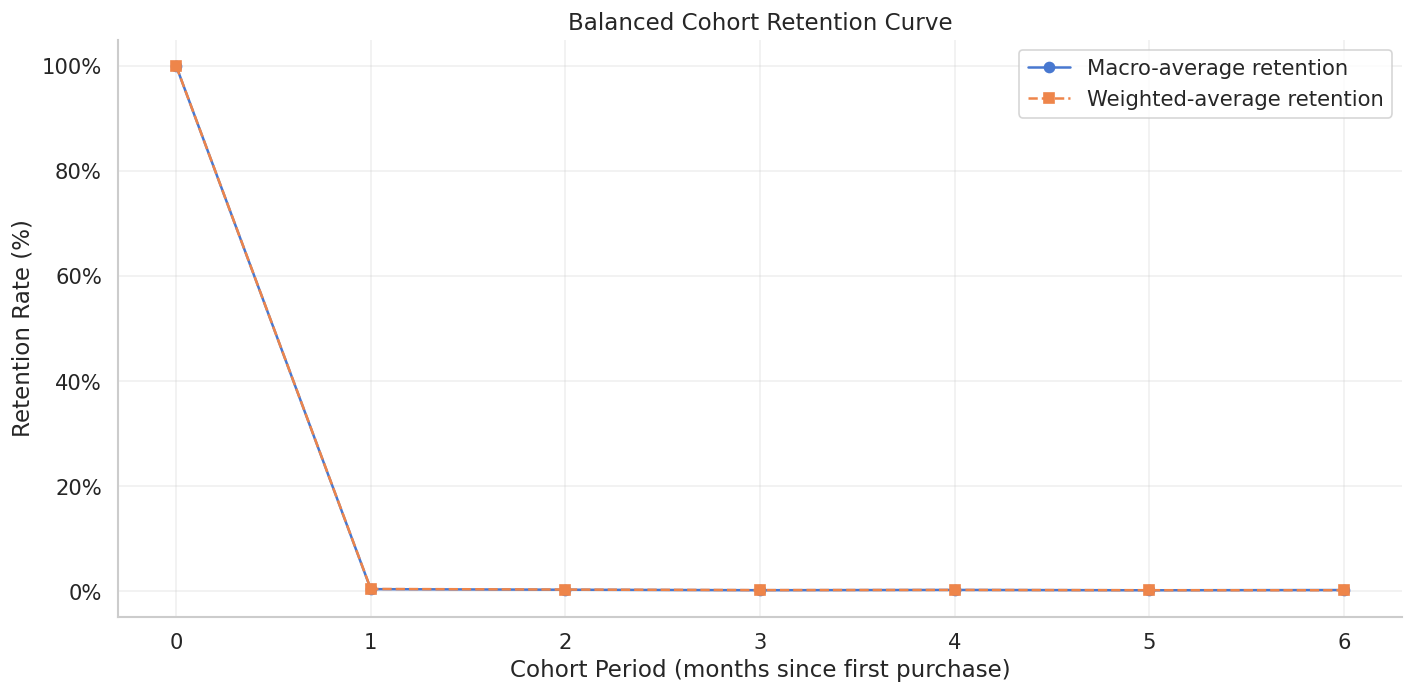

In [46]:
MAX_EVALUATION_PERIOD = 6

# Cohorts with enough follow-up history AND eligible acquisition size
bc = cohort.balanced_curve(max_period=MAX_EVALUATION_PERIOD)

fig, ax = plt.subplots(figsize=(12, 6))
periods = bc.macro.index.astype(int)
ax.plot(
    periods,
    bc.macro.values,
    marker='o',
    label='Macro-average retention',
)
ax.plot(
    periods,
    bc.weighted.values,
    marker='s',
    linestyle='--',
    label='Weighted-average retention',
)
ax.set_title('Balanced Cohort Retention Curve')
ax.set_xlabel('Cohort Period (months since first purchase)')
ax.set_ylabel('Retention Rate (%)')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.set_xticks(list(periods))
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

<br>

#### Month-1 Retention for Eligible Cohorts

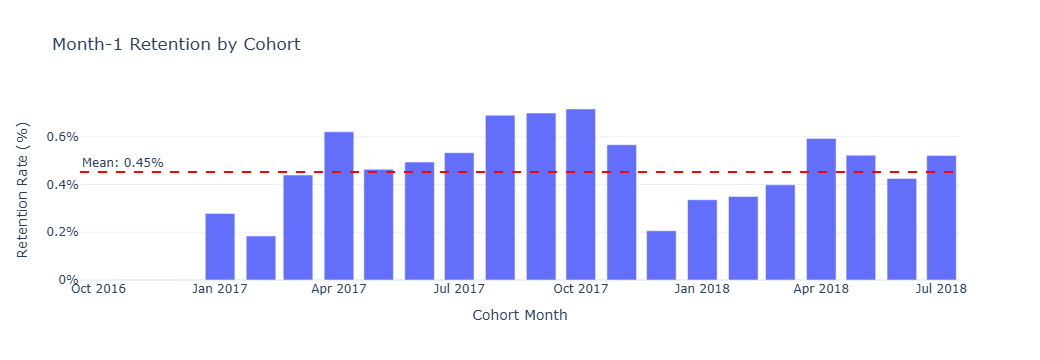

In [47]:
# Month-1 retention for eligible cohorts (percent), via CohortAnalyzer
month_1_retention = cohort.period_retention(1)

# Create figures with Plotly Graph Objects
fig = go.Figure()

# Adding a Bar Chart
fig.add_trace(go.Bar(
    x=month_1_retention.index.strftime('%Y-%m'),
    y=month_1_retention.values,
    name='Retention Rate',
    hovertemplate='Cohort Month: %{x}<br>Retention Rate: %{y:.2f}%<extra></extra>',
))
# Adding a mean value line
fig.add_hline(
    y=month_1_retention.mean(),
    line_dash="dash",
    line_color="red",
    annotation_text=f"Mean: {month_1_retention.mean():.2f}%",
    annotation_position="top left"
)
# Adjusting the layout
fig.update_layout(
    title='Month-1 Retention by Cohort',
    xaxis_title='Cohort Month',
    yaxis_title='Retention Rate (%)',
    xaxis=dict(tickangle=-0),
    yaxis=dict(ticksuffix='%'),
    template='plotly_white',
    hovermode='x unified'
)
fig.show()

In [48]:
# ══════════════════════════════════════════════════════════════════════
# Part B - Feasibility Proof
# Computes cohort retention rates from the Step 18 pipeline above.
# Uses cohort_counts (raw counts) and eligible_retention (rate table).
# ══════════════════════════════════════════════════════════════════════

# eligible_retention and eligible_counts are defined in the Diagnostics cell
# (cohorts with >= 50 customers at acquisition).
ret_m1 = eligible_retention[1].mean() * 100 if 1 in eligible_retention.columns else float('nan')
ret_m3 = eligible_retention[3].mean() * 100 if 3 in eligible_retention.columns else float('nan')
ret_m6 = eligible_retention[6].mean() * 100 if 6 in eligible_retention.columns else float('nan')
max_m1 = eligible_retention[1].max()  * 100 if 1 in eligible_retention.columns else float('nan')

print('=' * 62)
print('FEASIBILITY METRICS -- Part B (cohort retention rates)')
print(f'Eligible cohorts (>= 50 customers at acquisition): {len(eligible_cohorts)}')
print('=' * 62)
print(f'Average Month-1 retention : {ret_m1:.2f}%')
print(f'Average Month-3 retention : {ret_m3:.2f}%')
print(f'Average Month-6 retention : {ret_m6:.2f}%')
print(f'Best Month-1 (single cohort): {max_m1:.2f}%')
print()
print('Month-1 retention % per eligible cohort:')
m1_series = (
    eligible_retention[1]
    .dropna()
    .mul(100)
    .round(2)
)
m1_series.index = m1_series.index.strftime('%Y-%m')
print(m1_series.to_string())
print()
print(f'=> Typical Month-1 retention is {ret_m1:.2f}%  (max: {max_m1:.2f}%)')
print('   Confirms the one-time purchase pattern is structural, not a product issue.')

FEASIBILITY METRICS -- Part B (cohort retention rates)
Eligible cohorts (>= 50 customers at acquisition): 21
Average Month-1 retention : 0.45%
Average Month-3 retention : 0.24%
Average Month-6 retention : 0.27%
Best Month-1 (single cohort): 0.72%

Month-1 retention % per eligible cohort:
cohort_period
2016-10     0.0
2017-01    0.28
2017-02    0.18
2017-03    0.44
2017-04    0.62
2017-05    0.46
2017-06    0.49
2017-07    0.53
2017-08    0.69
2017-09     0.7
2017-10    0.72
2017-11    0.57
2017-12    0.21
2018-01    0.34
2018-02    0.35
2018-03     0.4
2018-04    0.59
2018-05    0.52
2018-06    0.43
2018-07    0.52

=> Typical Month-1 retention is 0.45%  (max: 0.72%)
   Confirms the one-time purchase pattern is structural, not a product issue.


---
## Export cleaned DataFrames for Streamlit

> Parquet preserves dtypes, is ~5× smaller than CSV, and loads ~10× faster. 
`Period` columns are serialised as strings and re-parsed in the dashboard.

In [49]:
OUTPUT_DIR = 'dashboard/data'
os.makedirs(OUTPUT_DIR, exist_ok=True)

def save_parquet(df, name):
    df_out = df.copy()
    for col in df_out.columns:
        if str(df_out[col].dtype).startswith('period'):
            df_out[col] = df_out[col].astype(str)
    path = f'{OUTPUT_DIR}/{name}.parquet'
    df_out.to_parquet(path, index=False)
    kb = os.path.getsize(path) / 1024
    print(f'  {name}.parquet — {df_out.shape[0]:,} rows x '
          f'{df_out.shape[1]} cols — {kb:.0f} KB')

print('Saving to', OUTPUT_DIR)
save_parquet(master_df,       'master_df')
save_parquet(delivered_df,    'delivered_df')
save_parquet(monthly_revenue, 'monthly_revenue')
save_parquet(category_stats,  'category_stats')
save_parquet(delivery_stats,  'delivery_stats')
save_parquet(state_revenue,   'state_revenue')
save_parquet(review_delivery, 'review_delivery')
save_parquet(rfm,             'rfm')

# Cohort tables: export ELIGIBLE cohorts only (>= MIN_COHORT_SIZE customers at
# acquisition), matching the conclusion heatmap. Unobserved periods stay NaN.
cohort_export = eligible_retention.copy()
cohort_export.index   = cohort_export.index.astype(str)
cohort_export.columns = cohort_export.columns.astype(str)
cohort_export.index.name = 'cohort_month'
cohort_export.to_parquet(f'{OUTPUT_DIR}/cohort_retention.parquet')
print(f'  cohort_retention.parquet — {cohort_export.shape}')

# Cohort acquisition sizes (period-0 entity counts) for dashboard filtering
sizes_export = eligible_counts[0].rename('cohort_size').to_frame()
sizes_export.index.name = 'cohort_month'
sizes_export.index     = sizes_export.index.astype(str)
sizes_export.to_parquet(f'{OUTPUT_DIR}/cohort_sizes.parquet')
print(f'  cohort_sizes.parquet — {sizes_export.shape}')
print('\nAll exports complete.')

Saving to dashboard/data
  master_df.parquet — 112,647 rows x 49 cols — 20902 KB
  delivered_df.parquet — 110,194 rows x 49 cols — 20396 KB
  monthly_revenue.parquet — 20 rows x 4 cols — 4 KB
  category_stats.parquet — 72 rows x 5 cols — 7 KB
  delivery_stats.parquet — 27 rows x 5 cols — 4 KB
  state_revenue.parquet — 27 rows x 6 cols — 5 KB
  review_delivery.parquet — 11 rows x 4 cols — 3 KB
  rfm.parquet — 93,357 rows x 10 cols — 3503 KB
  cohort_retention.parquet — (21, 21)
  cohort_sizes.parquet — (21, 1)

All exports complete.


---
## Conclusion & Recommendations

This section synthesises findings from all five business questions,
the RFM segmentation, and the cohort retention analysis into a set of
data-backed conclusions and prioritised recommendations.


<br>

### RFM Segment Summary -- Visual

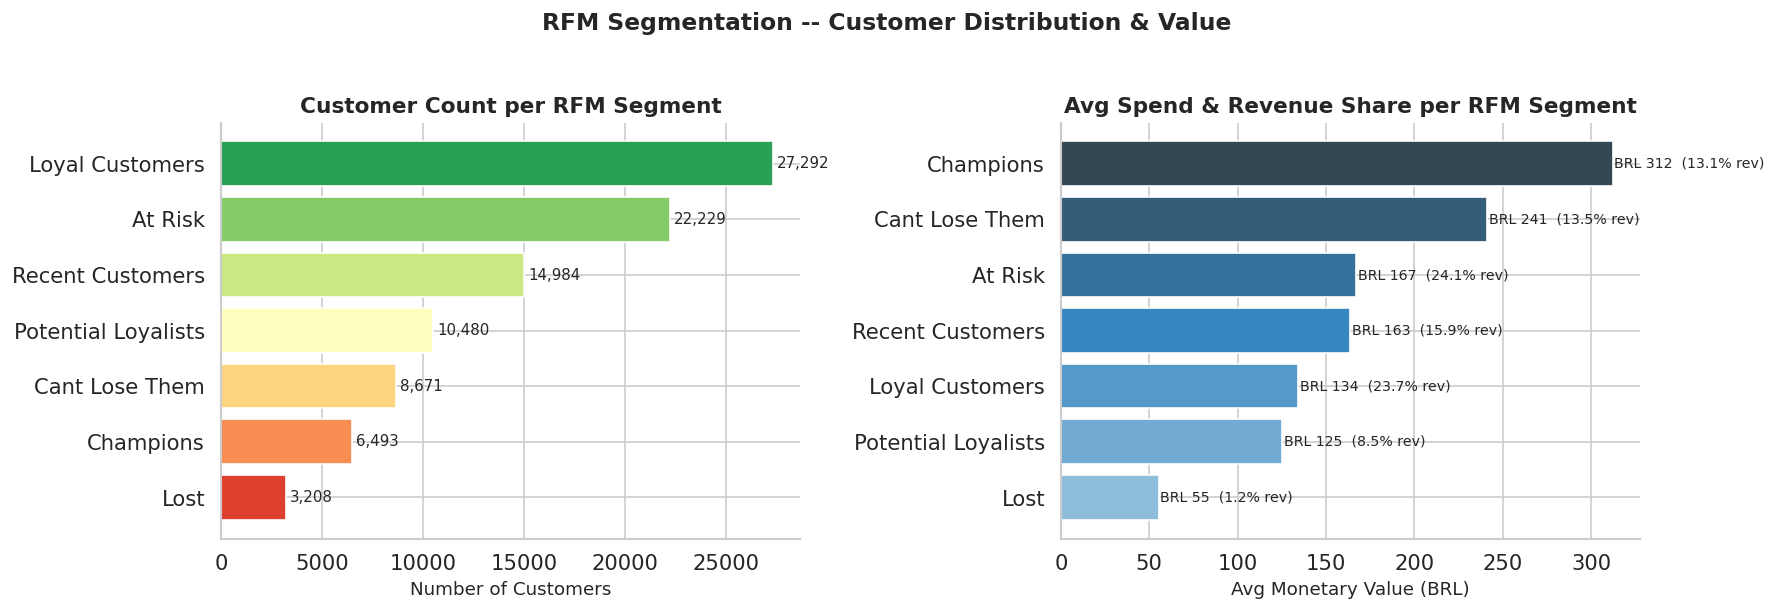

Saved: conclusion_rfm_segments.png

            segment  customer_count  avg_monetary  avg_recency  total_revenue  revenue_share_pct
          Champions            6493    312.129499    91.111813     2026656.84               13.1
     Cant Lose Them            8671    240.983039   394.553454     2089563.93               13.5
            At Risk           22229    166.979359   394.647847     3711784.17               24.1
   Recent Customers           14984    163.427972    90.878404     2448804.73               15.9
    Loyal Customers           27292    134.016898   144.225048     3657589.17               23.7
Potential Loyalists           10480    125.060724   248.750477     1310636.39                8.5
               Lost            3208     55.307525   474.703242      177426.54                1.2


In [50]:
# ── Segment size + avg monetary ──────────────────────────────────────────────
seg_summary = (
    rfm.groupby('segment', as_index=False)
    .agg(
        customer_count=('customer_unique_id', 'count'),
        avg_recency   =('recency',   'mean'),
        avg_frequency =('frequency', 'mean'),
        avg_monetary  =('monetary',  'mean'),
        total_revenue =('monetary',  'sum'),
    )
    .sort_values('avg_monetary', ascending=False)
)
seg_summary['revenue_share_pct'] = (
    seg_summary['total_revenue'] / seg_summary['total_revenue'].sum() * 100
).round(1)

# ── Seaborn — horizontal bar: customer count coloured by avg monetary ─────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

segment_order = seg_summary.sort_values('customer_count', ascending=True)['segment']
colors_seg = sns.color_palette('RdYlGn', n_colors=len(seg_summary))

bars = axes[0].barh(
    seg_summary.sort_values('customer_count')['segment'],
    seg_summary.sort_values('customer_count')['customer_count'],
    color=colors_seg
)
for bar, val in zip(
        bars,
        seg_summary.sort_values('customer_count')['customer_count']):
    axes[0].text(val + 200, bar.get_y() + bar.get_height() / 2,
                 f'{val:,}', va='center', fontsize=9)
axes[0].set_xlabel('Number of Customers', fontsize=11)
axes[0].set_title('Customer Count per RFM Segment',
                  fontsize=13, fontweight='bold')

# Right: avg monetary per segment
axes[1].barh(
    seg_summary.sort_values('avg_monetary')['segment'],
    seg_summary.sort_values('avg_monetary')['avg_monetary'],
    color=sns.color_palette('Blues_d', len(seg_summary))
)
for i, (_, row) in enumerate(
        seg_summary.sort_values('avg_monetary').iterrows()):
    axes[1].text(
        row['avg_monetary'] + 1, i,
        f"BRL {row['avg_monetary']:.0f}  ({row['revenue_share_pct']:.1f}% rev)",
        va='center', fontsize=8.5
    )
axes[1].set_xlabel('Avg Monetary Value (BRL)', fontsize=11)
axes[1].set_title('Avg Spend & Revenue Share per RFM Segment',
                  fontsize=13, fontweight='bold')

plt.suptitle('RFM Segmentation -- Customer Distribution & Value',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('dashboard/data/conclusion_rfm_segments.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: conclusion_rfm_segments.png')
print()
print(seg_summary[['segment','customer_count','avg_monetary',
                   'avg_recency','total_revenue','revenue_share_pct']].to_string(index=False))

<br>

### Cohort Retention Heatmap

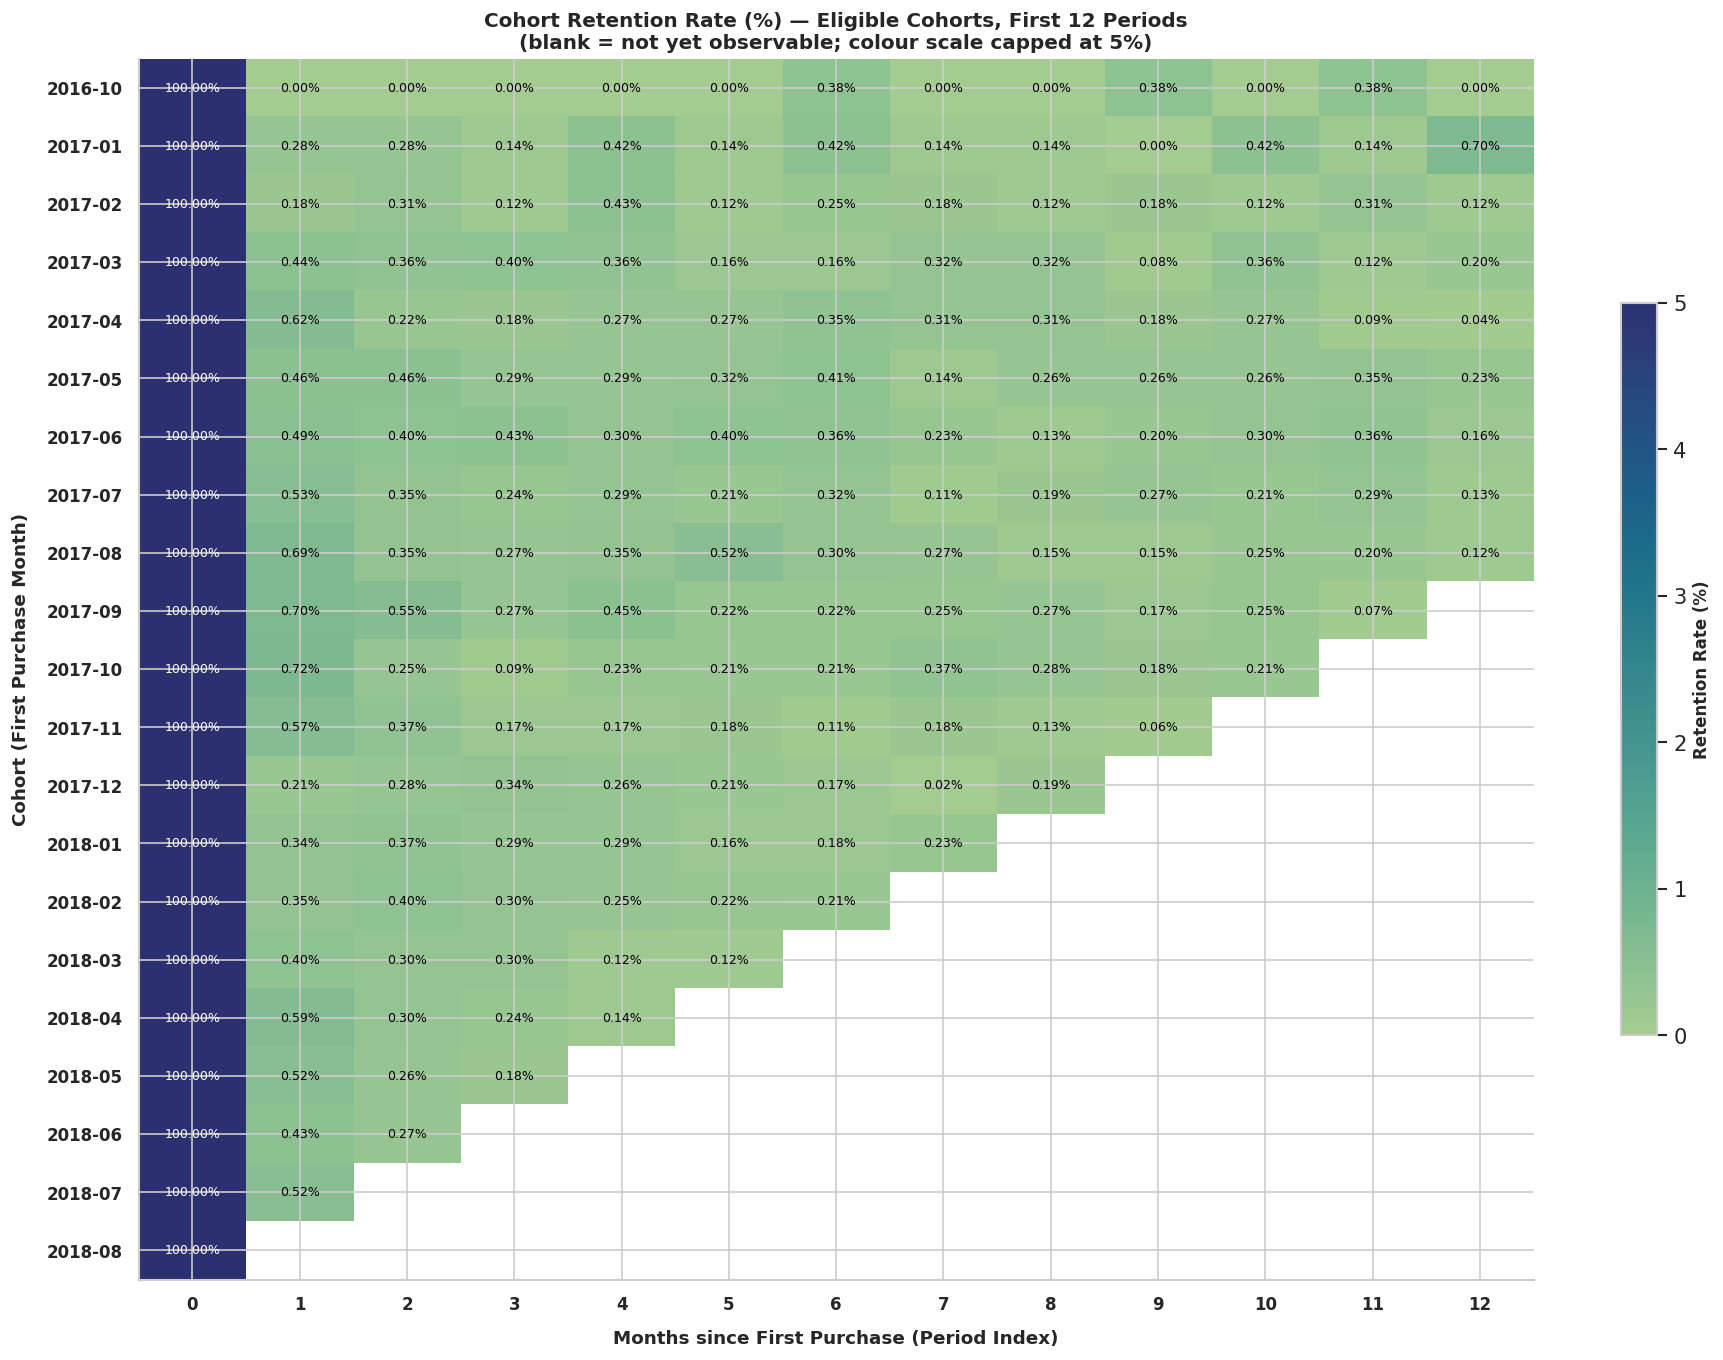

Saved: conclusion_cohort_retention.png
Avg Month-1 retention : 0.45%
Avg Month-3 retention : 0.24%
Avg Month-6 retention : 0.27%


In [51]:
# ── Conclusion: Cohort Retention Heatmap ─────────────────────────────────────
# Uses eligible_retention from Step 18 (cohorts >= 50 customers).
# Unobserved future periods are kept as NaN (not filled with 0)
# so the heatmap shows only what has actually been observed.

# Limit to first 13 periods (0..12) and convert to %
available_cols = [c for c in range(13) if c in eligible_retention.columns]
ret_pct = (eligible_retention[available_cols] * 100).copy()

# Mask zeros that represent unobserved future periods
# (a zero IS meaningful for period-0 = 100%, so keep col 0;
#  for periods > 0, genuine zeros stay; only unobserved NaN stay NaN)
# eligible_retention already has NaN for unobserved cells — no extra masking needed.
# Replace any residual 0.0 in periods > 0 that are actually NaN in cohort_counts
for col in available_cols[1:]:   # skip period-0
    # Where cohort_counts has NaN (unobserved), force ret_pct to NaN
    unobserved = eligible_counts[col].isna()
    ret_pct.loc[unobserved[unobserved].index, col] = np.nan

heatmap_data = (
    ret_pct
    .apply(pd.to_numeric, errors='coerce')
    .to_numpy(dtype=float, na_value=np.nan)
)

# String index for readable y-axis labels
y_labels = [idx.strftime('%Y-%m') for idx in eligible_retention.index]
x_labels = [str(c) for c in available_cols]

fig, ax = plt.subplots(figsize=(16, max(5, len(y_labels) * 0.55)))
img = ax.imshow(
    heatmap_data,
    aspect='auto',
    cmap='crest',
    vmin=0, vmax=5,          # focus the colour scale on 0–5% (the actual range)
)
ax.set_xticks(np.arange(len(x_labels)))
ax.set_xticklabels(x_labels, fontsize=10, fontweight='bold')
ax.set_yticks(np.arange(len(y_labels)))
ax.set_yticklabels(y_labels, fontsize=10, fontweight='bold')
ax.set_xlabel('Months since First Purchase (Period Index)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel('Cohort (First Purchase Month)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_title(
    'Cohort Retention Rate (%) — Eligible Cohorts, First 12 Periods\n'
    '(blank = not yet observable; colour scale capped at 5%)',
    fontsize=12, fontweight='bold'
)
cb = fig.colorbar(img, ax=ax, shrink=0.6)
cb.set_label('Retention Rate (%)', fontsize=10, fontweight='bold')

# Annotate every observed cell with f'{value:.2f}%'
for row_i in range(heatmap_data.shape[0]):
    for col_i in range(heatmap_data.shape[1]):
        val = heatmap_data[row_i, col_i]
        if not np.isnan(val):
            ax.text(
                col_i, row_i,
                f'{val:.2f}%',
                ha='center', va='center', 
                fontsize=7.5, fontweight='medium',
                color='black' if val < 2.5 else 'white',
            )

plt.tight_layout()
plt.savefig('dashboard/data/conclusion_cohort_retention.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: conclusion_cohort_retention.png')

# Quick stats
m1_avg = ret_pct[1].mean() if 1 in ret_pct.columns else float('nan')
m3_avg = ret_pct[3].mean() if 3 in ret_pct.columns else float('nan')
m6_avg = ret_pct[6].mean() if 6 in ret_pct.columns else float('nan')
print(f'Avg Month-1 retention : {m1_avg:.2f}%')
print(f'Avg Month-3 retention : {m3_avg:.2f}%')
print(f'Avg Month-6 retention : {m6_avg:.2f}%')

---
### Conclusions

#### 1. Strong Revenue Growth -- but Highly Concentrated
Monthly revenue grew dramatically from the platform's soft launch in late 2016
to a mature ~BRL 1M+ run-rate by mid-2018, with a clear Black Friday spike in
November 2017 (peak: BRL 1.15M, 7,289 orders). However, **São Paulo alone
accounts for 37.4% of all revenue**, and the top 3 states (SP, RJ, MG) control
62.5%. The remaining 24 states share 37.5%, and 13 states generate less than 1%
each. This concentration is both a strength (deep penetration in the core market)
and a risk (high sensitivity to a single regional economy).

#### 2. Category Leadership Does Not Guarantee Satisfaction
`health_beauty` leads in revenue (BRL 1.41M) but scores a respectable 4.19.
`bed_bath_table` earns BRL 1.23M but drops to 3.92 -- below the platform average
of 4.03. The worst-scoring categories (office_furniture, security_surveillance)
cluster around 3.5 and likely suffer from sizing mismatches, assembly issues, or
fragile-item damage in transit. Conversely, niche categories like
`luggage_accessories` (4.35) and `stationery` (4.25) punch above their revenue
weight in satisfaction -- a signal of under-tapped high-satisfaction verticals.

#### 3. Delivery Speed Is the Single Biggest Lever for Customer Satisfaction
The data is unambiguous: **late orders score 2.27 vs 4.29 for on-time/early
orders -- a 2.02-point drop** (on a 5-point scale). The overall late rate is 9.1%,
but it reaches 21.4% in Alagoas (AL) and exceeds 15% in several north-eastern
states. São Paulo delivers in 8.3 days on average; Alagoas takes 24 days. The
implication is direct: every percentage point reduction in late deliveries
translates measurably into higher review scores and, by extension, repeat intent.

#### 4. One-Time Buying Is the Norm -- Retention Is Near Zero
**96.9% of customers purchased only once** during the 2-year window. Cohort
retention at month 1 averages just ~0.4% and never exceeds 1% even at
month 12 for any cohort. This is typical for a B2C marketplace driven by
organic/SEO discovery (each search leads to a purchase, not a brand relationship).
However, it means Olist's monetisation depends almost entirely on **acquiring
new customers** rather than retaining existing ones -- a structurally expensive
model with no natural ceiling on CAC growth.

#### 5. RFM Reveals Actionable Value Tiers Despite Low Frequency
Even with frequency ≈ 1 for nearly all customers, RFM segmentation surfaces
meaningful tiers:
- **Champions** (6,493 customers): bought recently, avg BRL 312 spend.
  These are the platform's most valuable customers.
- **At Risk** (22,229 customers): haven't bought in ~395 days, avg BRL 167.
  Large group that could be reactivated.
- **Lost** (3,208 customers): last purchase 475 days ago, avg BRL 55.
  Likely gone; reactivation cost exceeds expected return.
- **Loyal Customers** (27,292): the largest segment -- recent buyers with
  moderate spend (BRL 134). The highest-volume opportunity for upsell.

#### 6. Installment Financing Unlocks Larger Purchases
Credit cards account for 75.3% of payments. Customers using 12 installments
spend **3.3× more** (BRL 327 vs BRL 100) than single-payment buyers.
This strong multiplier suggests that installment availability is a genuine
purchasing enabler, not just a convenience feature. The peak purchase hour
(16:00) and weekday concentration (Mon--Fri afternoons) confirm that the
primary buyer is a working adult shopping during/after work hours.

---
### Recommendations

Recommendations are grouped by impact area and prioritised
(**High / Medium / Low**) based on data-backed evidence.


In [52]:
# ── Recommendations summary table (printed for notebook, replicated in dashboard) ──

recs = pd.DataFrame([
    {
        'Priority': 'High',
        'Area'    : 'Delivery & Logistics',
        'Recommendation': 'SLA enforcement for north-eastern states',
        'Evidence': 'AL late rate 21.4%; late orders score 2.27 vs 4.29 (+2.02 pts if fixed)',
        'Expected Impact': 'Direct review score uplift → higher conversion on future visits',
    },
    {
        'Priority': 'High',
        'Area'    : 'Customer Retention',
        'Recommendation': 'Launch re-engagement campaign for At Risk segment (22,229 customers)',
        'Evidence': '~395 days since last purchase; avg BRL 167 spend per order',
        'Expected Impact': 'Even 5% reactivation rate = ~1,111 orders × BRL 167 = BRL 185K revenue',
    },
    {
        'Priority': 'High',
        'Area'    : 'Customer Retention',
        'Recommendation': 'Design a post-purchase loyalty loop (loyalty points, exclusive offers) to break the one-time purchase pattern',
        'Evidence': '96.9% of customers buy only once; month-1 retention < 0.5% across all cohorts',
        'Expected Impact': 'Moving retention from 0.4% to 2% would double LTV at no extra CAC',
    },
    {
        'Priority': 'Medium',
        'Area'    : 'Product & Category',
        'Recommendation': 'Enforce logistics quality standards for bed_bath_table and office_furniture sellers',
        'Evidence': 'bed_bath_table: BRL 1.23M revenue but 3.92 review; office_furniture: 3.51',
        'Expected Impact': '+0.3 review pts on high-revenue categories → improved search ranking & repeat rate',
    },
    {
        'Priority': 'Medium',
        'Area'    : 'Geographic Expansion',
        'Recommendation': 'Targeted seller recruitment and ad spend in under-served states (13 states < 1% share each)',
        'Evidence': 'SP+RJ+MG = 62.5% of revenue; northern/north-eastern states deeply under-represented',
        'Expected Impact': 'Revenue diversification; reduces dependency on single regional economy',
    },
    {
        'Priority': 'Medium',
        'Area'    : 'Revenue & Monetisation',
        'Recommendation': 'Promote and expand installment payment options at checkout',
        'Evidence': '12-installment buyers spend 3.3× more (BRL 327 vs BRL 100)',
        'Expected Impact': 'Increases average order value; unlocks higher-ticket category purchases',
    },
    {
        'Priority': 'Medium',
        'Area'    : 'Seasonal Strategy',
        'Recommendation': 'Build a dedicated Black Friday / year-end campaign playbook',
        'Evidence': 'Nov 2017 peak = BRL 1.15M (2.2× the annual monthly average)',
        'Expected Impact': 'Capturing 10% more of the seasonal spike → ~BRL 115K incremental revenue',
    },
    {
        'Priority': 'Low',
        'Area'    : 'Product & Category',
        'Recommendation': 'Expand marketing spend behind high-satisfaction niche categories (luggage, stationery, small_appliances)',
        'Evidence': 'Review scores 4.22–4.35 but revenue < BRL 270K — undersized relative to quality',
        'Expected Impact': 'Grow high-NPS categories to anchor platform reputation',
    },
    {
        'Priority': 'Low',
        'Area'    : 'Customer Retention',
        'Recommendation': 'Suppress further re-engagement spend on Lost segment (3,208 customers)',
        'Evidence': 'Last purchase 475 days ago; avg BRL 55 spend — below reactivation cost threshold',
        'Expected Impact': 'Reallocates budget to higher-ROI At Risk and Champions segments',
    },
    {
        'Priority': 'Low',
        'Area'    : 'Timing & UX',
        'Recommendation': 'Schedule promotional push notifications / emails for 14:00–16:00 on weekdays',
        'Evidence': 'Peak purchase hour is 16:00; weekday afternoons dominate order heatmap',
        'Expected Impact': 'Higher open-to-purchase conversion on time-sensitive offers',
    },
])

pd.set_option('display.max_colwidth', 80)
pd.set_option('display.max_rows', 20)
print(recs[['Priority','Area','Recommendation']].to_string(index=False))

Priority                   Area                                                                                                Recommendation
    High   Delivery & Logistics                                                                      SLA enforcement for north-eastern states
    High     Customer Retention                                          Launch re-engagement campaign for At Risk segment (22,229 customers)
    High     Customer Retention Design a post-purchase loyalty loop (loyalty points, exclusive offers) to break the one-time purchase pattern
  Medium     Product & Category                           Enforce logistics quality standards for bed_bath_table and office_furniture sellers
  Medium   Geographic Expansion                   Targeted seller recruitment and ad spend in under-served states (13 states < 1% share each)
  Medium Revenue & Monetisation                                                    Promote and expand installment payment options at checkout
  Medi

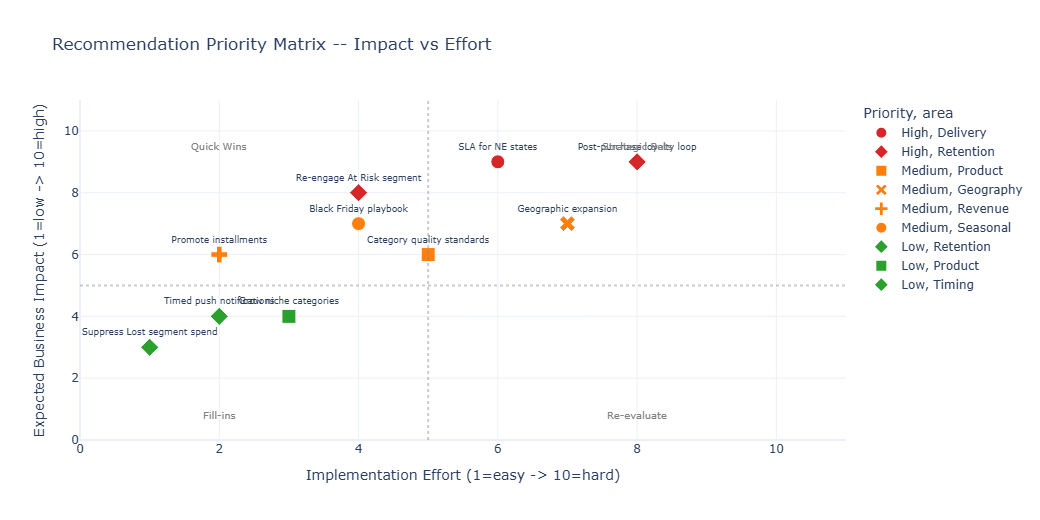

In [53]:
# ── Plotly — recommendation matrix (effort vs impact) ───────────────────────
rec_plot = pd.DataFrame([
    dict(rec='SLA for NE states',           impact=9, effort=6, priority='High',   area='Delivery'),
    dict(rec='Re-engage At Risk segment',   impact=8, effort=4, priority='High',   area='Retention'),
    dict(rec='Post-purchase loyalty loop',  impact=9, effort=8, priority='High',   area='Retention'),
    dict(rec='Category quality standards',  impact=6, effort=5, priority='Medium', area='Product'),
    dict(rec='Geographic expansion',        impact=7, effort=7, priority='Medium', area='Geography'),
    dict(rec='Promote installments',        impact=6, effort=2, priority='Medium', area='Revenue'),
    dict(rec='Black Friday playbook',       impact=7, effort=4, priority='Medium', area='Seasonal'),
    dict(rec='Grow niche categories',       impact=4, effort=3, priority='Low',    area='Product'),
    dict(rec='Suppress Lost segment spend', impact=3, effort=1, priority='Low',    area='Retention'),
    dict(rec='Timed push notifications',    impact=4, effort=2, priority='Low',    area='Timing'),
])

color_map = {'High': '#d62728', 'Medium': '#ff7f0e', 'Low': '#2ca02c'}

fig_rec = px.scatter(
    rec_plot,
    x='effort', y='impact',
    text='rec',
    color='priority',
    color_discrete_map=color_map,
    symbol='area',
    size=[12]*len(rec_plot),
    labels={'effort': 'Implementation Effort (1=easy -> 10=hard)',
            'impact': 'Expected Business Impact (1=low -> 10=high)',
            'priority': 'Priority'},
    title='Recommendation Priority Matrix -- Impact vs Effort',
    template=PLOTLY_TEMPLATE,
    height=520,
)
fig_rec.update_traces(
    textposition='top center', 
    textfont_size=9,
    marker=dict(size=14, line=dict(width=1, color='white'))
)
fig_rec.add_hline(
    y=5, 
    line_dash='dot', 
    line_color='gray', 
    opacity=0.4,
)
fig_rec.add_vline(
    x=5, 
    line_dash='dot', 
    line_color='gray', 
    opacity=0.4,
)
fig_rec.add_annotation(
    x=2, 
    y=9.5, 
    text='Quick Wins', 
    showarrow=False,
    font=dict(color='gray', size=10)
)
fig_rec.add_annotation(
    x=8, 
    y=9.5, 
    text='Strategic Bets', 
    showarrow=False,
    font=dict(color='gray', size=10)
)
fig_rec.add_annotation(
    x=2, 
    y=0.8, 
    text='Fill-ins', 
    showarrow=False,
    font=dict(color='gray', size=10)
)
fig_rec.add_annotation(
    x=8, 
    y=0.8, 
    text='Re-evaluate', 
    showarrow=False,
    font=dict(color='gray', size=10)
)
fig_rec.update_xaxes(range=[0, 11])
fig_rec.update_yaxes(range=[0, 11])
fig_rec.show()

### Final Summary

| Theme | Key Finding | Top Recommendation |
|---|---|---|
| **Revenue growth** | Grew from near-zero to BRL 1M+/month in 2 years | Build seasonal playbook (Black Friday) |
| **Geographic concentration** | SP + RJ + MG = 62.5% of revenue | Recruit sellers & run ads in under-served states |
| **Category quality gap** | High-revenue ≠ high satisfaction | Enforce logistics SLAs per category |
| **Delivery performance** | Late delivery drops score by 2.02 pts | Carrier SLA enforcement in north-eastern states |
| **Customer retention** | 96.9% buy only once; cohort retention < 0.5% | Design a post-purchase loyalty programme |
| **RFM value tiers** | 22K At Risk customers hold BRL 167 avg spend | Targeted re-engagement campaign |
| **Payment behaviour** | 12-instalment buyers spend 3.3× more | Promote instalment options at checkout |

> **The single highest-leverage action** is reducing late deliveries in
> north-eastern states. The 2-point review score improvement it unlocks
> improves marketplace search ranking, drives conversion, and compounds
> into every other metric -- retention, category growth, and geographic expansion.
